In [31]:
%matplotlib inline
import glob, os, sys, timeit
import matplotlib
import numpy as np
import pandas as pd

sys.path.append('../')
from pyqsofit.PyQSOFit import QSOFit
from astropy.io import fits
from astropy.table import Table
from astropy import units as u
from astropy.constants import c
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

QSOFit.set_mpl_style()
import astropy
import lmfit
import pyqsofit
import emcee 

In [2]:
path_ex = '.' #os.path.join(pyqsofit.__path__[0], '..', 'example')

# create a header
hdr0 = fits.Header()
hdr0['Author'] = 'Kanyuni Iemoto'
primary_hdu = fits.PrimaryHDU(header=hdr0)

In [3]:
line_priors = np.rec.array([
    (6564.61, 'Ha', 6400, 6800, 'Ha_br', 2, 0.0, 0.0, 1e10, 5e-3, 0.004, 0.05, 0.015, 0, 0, 0, 0.05, 1),
    (6564.61, 'Ha', 6400, 6800, 'Ha_na', 1, 0.0, 0.0, 1e10, 1e-3, 5e-4, 0.00169, 0.01, 1, 1, 0, 0.002, 1),
    (6549.85, 'Ha', 6400, 6800, 'NII6549', 1, 0.0, 0.0, 1e10, 1e-3, 2.3e-4, 0.00169, 5e-3, 1, 1, 1, 0.001, 1),
    (6585.28, 'Ha', 6400, 6800, 'NII6585', 1, 0.0, 0.0, 1e10, 1e-3, 2.3e-4, 0.00169, 5e-3, 1, 1, 1, 0.003, 1),
    (6718.29, 'Ha', 6400, 6800, 'SII6718', 1, 0.0, 0.0, 1e10, 1e-3, 2.3e-4, 0.00169, 5e-3, 1, 1, 2, 0.001, 1),
    (6732.67, 'Ha', 6400, 6800, 'SII6732', 1, 0.0, 0.0, 1e10, 1e-3, 2.3e-4, 0.00169, 5e-3, 1, 1, 2, 0.001, 1),

    (4862.68, 'Hb', 4640, 5100, 'Hb_br', 2, 0.0, 0.0, 1e10, 5e-3, 0.004, 0.05, 0.01, 0, 0, 0, 0.01, 1),
    (4862.68, 'Hb', 4640, 5100, 'Hb_na', 1, 0.0, 0.0, 1e10, 1e-3, 2.3e-4, 0.00169, 0.01, 1, 1, 0, 0.002, 1),
    (4960.30, 'Hb', 4640, 5100, 'OIII4959c', 1, 0.0, 0.0, 1e10, 1e-3, 2.3e-4, 0.00169, 0.01, 1, 1, 0, 0.002, 1),
    (5008.24, 'Hb', 4640, 5100, 'OIII5007c', 1, 0.0, 0.0, 1e10, 1e-3, 2.3e-4, 0.00169, 0.01, 1, 1, 0, 0.004, 1),
    (4960.30, 'Hb', 4640, 5100, 'OIII4959w',   1, 0.0, 0.0, 1e10, 3e-3, 2.3e-4, 0.004,  0.01,  2, 2, 0, 0.001, 1),
    (5008.24, 'Hb', 4640, 5100, 'OIII5007w',   1, 0.0, 0.0, 1e10, 3e-3, 2.3e-4, 0.004,  0.01,  2, 2, 0, 0.002, 1),
    #(4687.02, 'Hb', 4640, 5100, 'HeII4687_br', 1, 0.0, 0.0, 1e10, 5e-3, 0.004,  0.05,   0.005, 0, 0, 0, 0.001, 1),
    #(4687.02, 'Hb', 4640, 5100, 'HeII4687_na', 1, 0.0, 0.0, 1e10, 1e-3, 2.3e-4, 0.00169, 0.005, 1, 1, 0, 0.001, 1),

    #(3934.78, 'CaII', 3900, 3960, 'CaII3934' , 2, 0.0, 0.0, 1e10, 1e-3, 3.333e-4, 0.00169, 0.01, 99, 0, 0, -0.001, 1),

    #(3728.48, 'OII', 3650, 3800, 'OII3728', 1, 0.0, 0.0, 1e10, 1e-3, 3.333e-4, 0.00169, 0.01, 1, 1, 0, 0.001, 1),

    #(3426.84, 'NeV', 3380, 3480, 'NeV3426',    1, 0.0, 0.0, 1e10, 1e-3, 3.333e-4, 0.00169, 0.01, 0, 0, 0, 0.001, 1),
    #(3426.84, 'NeV', 3380, 3480, 'NeV3426_br', 1, 0.0, 0.0, 1e10, 5e-3, 0.0025,   0.02,   0.01, 0, 0, 0, 0.001, 1),

    (2798.75, 'MgII', 2700, 2900, 'MgII_br', 2, 0.0, 0.0, 1e10, 5e-3, 0.004, 0.05, 0.015, 0, 0, 0, 0.05, 1),
    (2798.75, 'MgII', 2700, 2900, 'MgII_na', 1, 0.0, 0.0, 1e10, 1e-3, 5e-4, 0.00169, 0.01, 1, 1, 0, 0.002, 1),

    (1908.73, 'CIII', 1700, 1970, 'CIII_br', 2, 0.0, 0.0, 1e10, 5e-3, 0.004, 0.05, 0.015, 99, 0, 0, 0.01, 1),
    #(1908.73, 'CIII', 1700, 1970, 'CIII_na',   1, 0.0, 0.0, 1e10, 1e-3, 5e-4,  0.00169, 0.01,  1, 1, 0, 0.002, 1),
    #(1892.03, 'CIII', 1700, 1970, 'SiIII1892', 1, 0.0, 0.0, 1e10, 2e-3, 0.001, 0.015,  0.003, 1, 1, 0, 0.005, 1),
    #(1857.40, 'CIII', 1700, 1970, 'AlIII1857', 1, 0.0, 0.0, 1e10, 2e-3, 0.001, 0.015,  0.003, 1, 1, 0, 0.005, 1),
    #(1816.98, 'CIII', 1700, 1970, 'SiII1816',  1, 0.0, 0.0, 1e10, 2e-3, 0.001, 0.015,  0.01,  1, 1, 0, 0.0002, 1),
    #(1786.7,  'CIII', 1700, 1970, 'FeII1787',  1, 0.0, 0.0, 1e10, 2e-3, 0.001, 0.015,  0.01,  1, 1, 0, 0.0002, 1),
    #(1750.26, 'CIII', 1700, 1970, 'NIII1750',  1, 0.0, 0.0, 1e10, 2e-3, 0.001, 0.015,  0.01,  1, 1, 0, 0.001, 1),
    #(1718.55, 'CIII', 1700, 1900, 'NIV1718',   1, 0.0, 0.0, 1e10, 2e-3, 0.001, 0.015,  0.01,  1, 1, 0, 0.001, 1),

    (1549.06, 'CIV', 1500, 1700, 'CIV_br', 2, 0.0, 0.0, 1e10, 5e-3, 0.004, 0.05, 0.015, 0, 0, 0, 0.05, 1),
    # (1549.06, 'CIV', 1500, 1700, 'CIV_na', 1, 0.0, 0.0, 1e10, 1e-3, 5e-4, 0.00169, 0.01, 1, 1, 0, 0.002, 1),
    #(1640.42, 'CIV', 1500, 1700, 'HeII1640',    1, 0.0, 0.0, 1e10, 1e-3, 5e-4,   0.00169, 0.008, 1, 1, 0, 0.002, 1),
    #(1663.48, 'CIV', 1500, 1700, 'OIII1663',    1, 0.0, 0.0, 1e10, 1e-3, 5e-4,   0.00169, 0.008, 1, 1, 0, 0.002, 1),
    #(1640.42, 'CIV', 1500, 1700, 'HeII1640_br', 1, 0.0, 0.0, 1e10, 5e-3, 0.0025, 0.02,   0.008, 1, 1, 0, 0.002, 1),
    #(1663.48, 'CIV', 1500, 1700, 'OIII1663_br', 1, 0.0, 0.0, 1e10, 5e-3, 0.0025, 0.02,   0.008, 1, 1, 0, 0.002, 1),

    #(1402.06, 'SiIV', 1290, 1450, 'SiIV_OIV1', 1, 0.0, 0.0, 1e10, 5e-3, 0.002, 0.05,  0.015, 1, 1, 0, 0.05, 1),
    #(1396.76, 'SiIV', 1290, 1450, 'SiIV_OIV2', 1, 0.0, 0.0, 1e10, 5e-3, 0.002, 0.05,  0.015, 1, 1, 0, 0.05, 1),
    #(1335.30, 'SiIV', 1290, 1450, 'CII1335',   1, 0.0, 0.0, 1e10, 2e-3, 0.001, 0.015, 0.01,  1, 1, 0, 0.001, 1),
    #(1304.35, 'SiIV', 1290, 1450, 'OI1304',    1, 0.0, 0.0, 1e10, 2e-3, 0.001, 0.015, 0.01,  1, 1, 0, 0.001, 1),

    (1215.67, 'Lya', 1150, 1290, 'Lya_br', 3, 0.0, 0.0, 1e10, 5e-3, 0.002, 0.05, 0.02, 0, 0, 0, 0.05, 1),
    (1240.14, 'Lya', 1150, 1290, 'NV1240', 1, 0.0, 0.0, 1e10, 2e-3, 0.001, 0.01, 0.005, 0, 0, 0, 0.002, 1),
    # (1215.67, 'Lya', 1150, 1290, 'Lya_na', 1, 0.0, 0.0, 1e10, 1e-3, 5e-4, 0.00169, 0.01, 0, 0, 0, 0.002, 1),
    ],

    formats='float32,    a20,  float32, float32,      a20,  int32, float32, float32, float32, float32, float32, float32, float32,   int32,  int32,  int32, float32, int32',
    names=' lambda, compname,   minwav,  maxwav, linename, ngauss,  inisca,  minsca,  maxsca,  inisig,  minsig,  maxsig,    voff,  vindex, windex, findex,  fvalue,  vary')

# Header
hdr1 = fits.Header()
hdr1['lambda'] = 'Vacuum Wavelength in Ang'
hdr1['minwav'] = 'Lower complex fitting wavelength range'
hdr1['maxwav'] = 'Upper complex fitting wavelength range'
hdr1['ngauss'] = 'Number of Gaussians for the line'

# Can be set to negative for absorption lines if you want
hdr1['inisca'] = 'Initial guess of line scale [flux]'
hdr1['minsca'] = 'Lower range of line scale [flux]'
hdr1['maxsca'] = 'Upper range of line scale [flux]'

hdr1['inisig'] = 'Initial guess of linesigma [lnlambda]'
hdr1['minsig'] = 'Lower range of line sigma [lnlambda]'
hdr1['maxsig'] = 'Upper range of line sigma [lnlambda]'

hdr1['voff  '] = 'Limits on velocity offset from the central wavelength [lnlambda]'
hdr1['vindex'] = 'Entries w/ same NONZERO vindex constrained to have same velocity'
hdr1['windex'] = 'Entries w/ same NONZERO windex constrained to have same width'
hdr1['findex'] = 'Entries w/ same NONZERO findex have constrained flux ratios'
hdr1['fvalue'] = 'Relative scale factor for entries w/ same findex'

hdr1['vary'] = 'Whether or not to vary the parameter (set to 0 to fix the line parameter to initial values)'

# Save line info
hdu1 = fits.BinTableHDU(data=line_priors, header=hdr1, name='line_priors')

In [4]:
conti_windows = np.rec.array([
    (1150., 1170.), 
    (1275., 1290.),
    (1350., 1360.),
    (1445., 1465.),
    (1690., 1705.),
    (1770., 1810.),
    (1970., 2400.),
    (2480., 2675.),
    (2925., 3400.),
    (3775., 3832.),
    (4000., 4050.),
    (4200., 4230.),
    (4435., 4640.),
    (5100., 5535.),
    (6005., 6035.),
    (6110., 6250.),
    (6800., 7000.),
    (7160., 7180.),
    (7500., 7800.),
    (8050., 8150.), # Continuum fitting windows (to avoid emission line, etc.)  [AA]
    ], 
    formats = 'float32,  float32',
    names =    'min,     max')

hdu2 = fits.BinTableHDU(data=conti_windows, name='conti_windows')

conti_priors = np.rec.array([
    ('Fe_uv_norm',  0.0,   0.0,   1e10,  1), # Normalization of the MgII Fe template [flux]
    ('Fe_uv_FWHM',  3000,  1200,  18000, 1), # FWHM of the MgII Fe template [AA]
    ('Fe_uv_shift', 0.0,   -0.01, 0.01,  1), # Wavelength shift of the MgII Fe template [lnlambda]
    ('Fe_op_norm',  0.0,   0.0,   1e10,  1), # Normalization of the Hbeta/Halpha Fe template [flux]
    ('Fe_op_FWHM',  3000,  1200,  18000, 1), # FWHM of the Hbeta/Halpha Fe template [AA]
    ('Fe_op_shift', 0.0,   -0.01, 0.01,  1), # Wavelength shift of the Hbeta/Halpha Fe template [lnlambda]
    ('PL_norm',     1.0,   0.0,   1e10,  1), # Normalization of the power-law (PL) continuum f_lambda = (lambda/3000)^-alpha
    ('PL_slope',    -1.5,  -5.0,  3.0,   1), # Slope of the power-law (PL) continuum
    ('Blamer_norm', 0.0,   0.0,   1e10,  1), # Normalization of the Balmer continuum at < 3646 AA [flux] (Dietrich et al. 2002)
    ('Balmer_Te',   15000, 10000, 50000, 1), # Te of the Balmer continuum at < 3646 AA [K?]
    ('Balmer_Tau',  0.5,   0.1,   2.0,   1), # Tau of the Balmer continuum at < 3646 AA
    ('conti_a_0',   0.0,   None,  None,  1), # 1st coefficient of the polynomial continuum
    ('conti_a_1',   0.0,   None,  None,  1), # 2nd coefficient of the polynomial continuum
    ('conti_a_2',   0.0,   None,  None,  1), # 3rd coefficient of the polynomial continuum
    # Note: The min/max bounds on the conti_a_0 coefficients are ignored by the code,
    # so they can be determined automatically for numerical stability.
    ],

    formats = 'a20,  float32, float32, float32, int32',
    names = 'parname, initial,   min,     max,     vary')

hdr3 = fits.Header()
hdr3['ini'] = 'Initial guess of line scale [flux]'
hdr3['min'] = 'FWHM of the MgII Fe template'
hdr3['max'] = 'Wavelength shift of the MgII Fe template'

hdr3['vary'] = 'Whether or not to vary the parameter (set to 0 to fix the continuum parameter to initial values)'


hdu3 = fits.BinTableHDU(data=conti_priors, header=hdr3, name='conti_priors')

In [5]:
# customize
measure_info = Table(
    [
        [[1350, 1450, 3000, 4200, 5100]],
        [[
            # [2240, 2650], 
            [4435, 4685],
        ]]
    ],
    names=([
        'cont_loc',
        'Fe_flux_range'
    ]),
    dtype=([
        'float32',
        'float32'
    ])
)
hdr4 = fits.Header()
hdr4['cont_loc'] = 'The wavelength of continuum luminosity in results'
hdr4['Fe_flux_range'] = 'Fe emission wavelength range calculated in results'

hdu4 = fits.BinTableHDU(data=measure_info, header=hdr4, name='measure_info')

hdu_list = fits.HDUList([primary_hdu, hdu1, hdu2, hdu3, hdu4])
hdu_list.writeto(os.path.join(path_ex, 'qsopar.fits'), overwrite=True)

In [6]:
path_out = '/work/11161/kanyuni/ls6/quassiQ_project/fitting'
# This is actually CLQ
bright = fits.open('/work/10579/prisha/ls6/desi_project/output_coadds/39633100518459964/coadd-5-1766-20210519-39633100518459964.fits')
# just setting but not actually using for now
dim = fits.open('/work/10579/prisha/ls6/desi_project/output_coadds/39633100518459964/coadd-9-11150-20220529-39633100518459964.fits')


In [7]:
from desispec.io import read_spectra
from desispec.coaddition import coadd_cameras

spectra = read_spectra(bright.filename())
combined = coadd_cameras(spectra)

print(spectra.bands, "->", combined.bands)
lam = combined.wave["brz"]         # observed wavelength in Å
flux = combined.flux["brz"][0]      # [0] selects your one target
ivar = combined.ivar["brz"][0]

good = (ivar > 0) & np.isfinite(ivar) & np.isfinite(flux)
lam = lam[good]
flux = flux[good]
err = 1 / np.sqrt(ivar[good])
ra = float(bright["FIBERMAP"].data["TARGET_RA"][0])
dec = float(bright["FIBERMAP"].data["TARGET_DEC"][0])

INFO:spectra.py:453:read_spectra: iotime 0.030 sec to read spectra from:  coadd-5-1766-20210519-39633100518459964.fits at 2026-11-28T00:27:30.909340
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.094 [sec]
['b', 'r', 'z'] -> ['brz']


In [8]:
# This FITS doesn't contain redshift 
catalog = pd.read_csv(
    "/work/10579/prisha/ls6/desi_project/final_subset.csv",
    usecols=["TARGETID", "Z"],
    dtype={"TARGETID": "int64"},
)

target_id = 39633100518459964
redshifts = catalog.loc[catalog["TARGETID"] == target_id, "Z"]

z = 2.23509931
q_mle = QSOFit(lam, flux, err, z, ra=ra, dec=dec, path=path_ex)

Name            Value      Min      Max   Stderr     Vary     Expr Brute_Step
Balmer_Tau        0.5      0.1        2     None    False     None     None
Balmer_Te     1.5e+04    1e+04    5e+04     None    False     None     None
Blamer_norm         0        0    1e+10     None    False     None     None
Fe_op_FWHM       3000     1200  1.8e+04     None    False     None     None
Fe_op_norm          0        0    1e+10     None    False     None     None
Fe_op_shift         0    -0.01     0.01     None    False     None     None
Fe_uv_FWHM       3000     1200  1.8e+04     None     True     None     None
Fe_uv_norm          0        0    1e+10     None     True     None     None
Fe_uv_shift         0    -0.01     0.01     None     True     None     None
PL_norm             1        0    1e+10     None     True     None     None
PL_slope         -1.5       -5        3     None     True     None     None
conti_a_0           0     -inf      inf     None     True     None     None
conti_a_1 

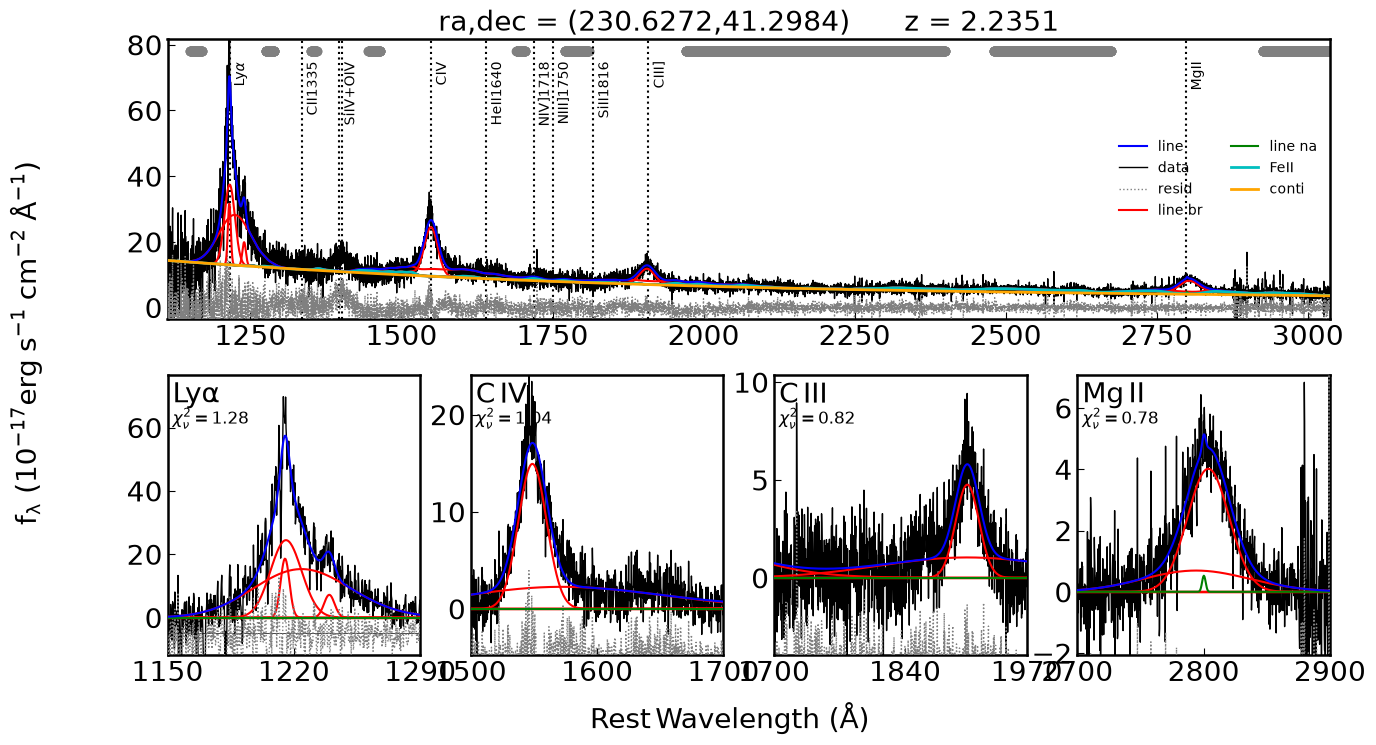

In [9]:
q_mle = QSOFit(lam, flux, err, z, ra=ra, dec=dec, path=path_ex)
start = timeit.default_timer()
q_mle.Fit(name=None,  # customize the name of given targets. Default: plate-mjd-fiber
          # prepocessing parameters
          nsmooth=1,  # do n-pixel smoothing to the raw input flux and err spectra
          and_mask=False,  # delete the and masked pixels
          or_mask=False,  # delete the or masked pixels
          reject_badpix=True,  # reject 10 most possible outliers by the test of pointDistGESD
          deredden=True,  # correct the Galactic extinction
          wave_range=None,  # trim input wavelength
          wave_mask=None,  # 2-D array, mask the given range(s)

          # host decomposition parameters
          decompose_host=True,  # If True, the host galaxy-QSO decomposition will be applied
          host_prior=False, # If True, the code will adopt prior-informed method to assist decomposition. Currently, only 'CZBIN1' and 'DZBIN1' model for QSO PCA are available. And the model for galaxy must be PCA too.
          host_prior_scale=0.2, # scale of prior panelty. Usually, 0.2 works fine for SDSS spectra. Adjust it smaller if you find the prior affect the fitting results too much.

          host_line_mask=True, # If True, the line region of galaxy will be masked when subtracted from original spectra.
          decomp_na_mask=True, # If True, the narrow line region will be masked when perform decomposition
          qso_type='CZBIN1', # PCA template name for quasar
          npca_qso=10, # numebr of quasar templates
          host_type='PCA', # template name for galaxy
          npca_gal=5, # number of galaxy templates
          
          # continuum model fit parameters
          Fe_uv_op=True,  # If True, fit continuum with UV and optical FeII template
          poly=True,  # If True, fit continuum with the polynomial component to account for the dust reddening
          BC=False,  # If True, fit continuum with Balmer continua from 1000 to 3646A
          initial_guess=None,  # Initial parameters for continuum model, read the annotation of this function for detail
          rej_abs_conti=False,  # If True, it will iterately reject 3 sigma outlier absorption pixels in the continuum
          n_pix_min_conti=100,  # Minimum number of negative pixels for host continuuum fit to be rejected.

          # emission line fit parameters
          linefit=True,  # If True, the emission line will be fitted
          rej_abs_line=False,
          # If True, it will iterately reject 3 sigma outlier absorption pixels in the emission lines

          # fitting method selection
          MC=False,
          # If True, do Monte Carlo resampling of the spectrum based on the input error array to produce the MC error array
          MCMC=False,
          # If True, do Markov Chain Monte Carlo sampling of the posterior probability densities to produce the error array
          nsamp=200,
          # The number of trials of the MC process (if MC=True) or number samples to run MCMC chain (if MCMC=True)

          # advanced fitting parameters
          param_file_name='qsopar.fits',  # Name of the qso fitting parameter FITS file.
          nburn=20,  # The number of burn-in samples to run MCMC chain
          nthin=10,  # To set the MCMC chain returns every n samples
          epsilon_jitter=0.,
          # Initial jitter for every initial guass to avoid local minimum. (Under test, not recommanded to change)

          # customize the results
          save_result=False,  # If True, all the fitting results will be saved to a fits file
          save_fits_name=None,  # The output name of the result fits
          save_fits_path=path_out,  # The output path of the result fits
          plot_fig=True,  # If True, the fitting results will be plotted
          save_fig=False,  # If True, the figure will be saved
          plot_corner=True,  # Whether or not to plot the corner plot results if MCMC=True

          # debugging mode
          verbose=True,  # turn on (True) or off (False) debugging output

          # sublevel parameters for figure plot and emcee
          kwargs_plot={
              'save_fig_path': '.',  # The output path of the figure
              'broad_fwhm'   : 1200  # km/s, lower limit that code decide if a line component belongs to broad component
          },
          kwargs_conti_emcee={},
          kwargs_line_emcee={})

end = timeit.default_timer()

print(f'Fitting finished in {np.round(end - start, 1)}s')

Name            Value      Min      Max   Stderr     Vary     Expr Brute_Step
Balmer_Tau        0.5      0.1        2     None    False     None     None
Balmer_Te     1.5e+04    1e+04    5e+04     None    False     None     None
Blamer_norm         0        0    1e+10     None    False     None     None
Fe_op_FWHM       3000     1200  1.8e+04     None    False     None     None
Fe_op_norm          0        0    1e+10     None    False     None     None
Fe_op_shift         0    -0.01     0.01     None    False     None     None
Fe_uv_FWHM       3000     1200  1.8e+04     None     True     None     None
Fe_uv_norm          0        0    1e+10     None     True     None     None
Fe_uv_shift         0    -0.01     0.01     None     True     None     None
PL_norm             1        0    1e+10     None     True     None     None
PL_slope         -1.5       -5        3     None     True     None     None
conti_a_0           0     -inf      inf     None     True     None     None
conti_a_1 

Fit report
[[Variables]]
    Fe_uv_norm:   0.14732937 +/- 0.00624405 (4.24%) (init = 0)
    Fe_uv_FWHM:   2779.39743 +/- 702.706078 (25.28%) (init = 3000)
    Fe_uv_shift: -3.2941e-04 +/- 8.4049e-04 (255.15%) (init = 0)
    Fe_op_norm:   0 (fixed)
    Fe_op_FWHM:   3000 (fixed)
    Fe_op_shift:  0 (fixed)
    PL_norm:      3.64422825 +/- 0.05224718 (1.43%) (init = 1)
    PL_slope:     2.58221668 +/- 3799.49590 (147140.86%) (init = -1.5)
    Blamer_norm:  0 (fixed)
    Balmer_Te:    15000 (fixed)
    Balmer_Tau:   0.5 (fixed)
    conti_a_0:   -5170.93316 +/- 4615880.76 (89265.91%) (init = 0)
    conti_a_1:   -1.23900765 +/- 3206.06723 (258760.89%) (init = 0)
    conti_a_2:   -0.00129466 +/- 0.56068662 (43307.52%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(PL_slope, conti_a_0)    = -1.0000
    C(conti_a_0, conti_a_1)   = +1.0000
    C(PL_slope, conti_a_1)    = -1.0000
    C(conti_a_1, conti_a_2)   = +1.0000
    C(conti_a_0, conti_a_2)   = +1.0000
    C(PL_slo

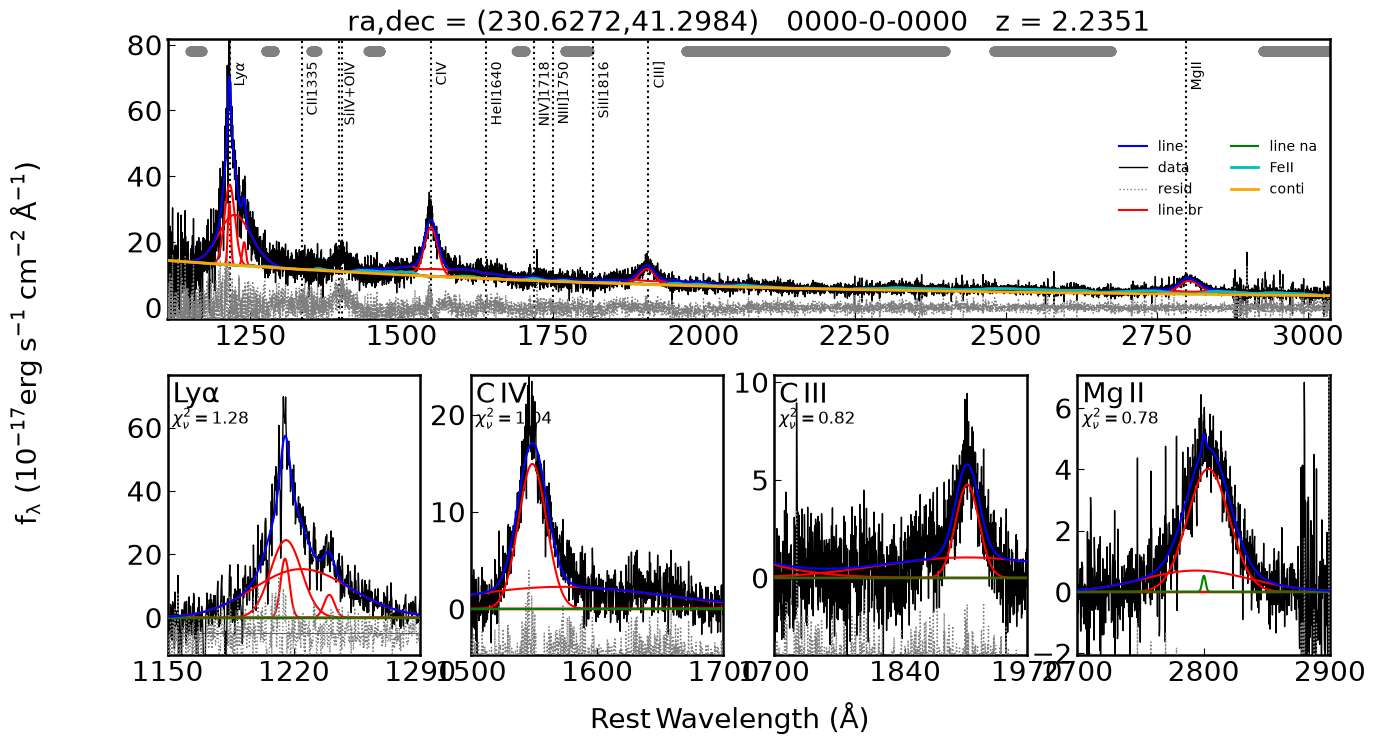

In [10]:
# whether if host_prior is true or not

start = timeit.default_timer()
# Do the fitting

q_mle.Fit(name=None,  # customize the name of given targets. Default: plate-mjd-fiber
          # prepocessing parameters
          nsmooth=1,  # do n-pixel smoothing to the raw input flux and err spectra
          and_mask=False,  # delete the and masked pixels
          or_mask=False,  # delete the or masked pixels
          reject_badpix=True,  # reject 10 most possible outliers by the test of pointDistGESD
          deredden=True,  # correct the Galactic extinction
          wave_range=None,  # trim input wavelength
          wave_mask=None,  # 2-D array, mask the given range(s)

          # host decomposition parameters
          decompose_host=True,  # If True, the host galaxy-QSO decomposition will be applied
          host_prior=True, # If True, the code will adopt prior-informed method to assist decomposition. Currently, only 'CZBIN1' and 'DZBIN1' model for QSO PCA are available. And the model for galaxy must be PCA too.
          host_prior_scale=0.2, # scale of prior panelty. Usually, 0.2 works fine for SDSS spectra. Adjust it smaller if you find the prior affect the fitting results too much.

          host_line_mask=True, # If True, the line region of galaxy will be masked when subtracted from original spectra.
          decomp_na_mask=True, # If True, the narrow line region will be masked when perform decomposition
          qso_type='CZBIN1', # PCA template name for quasar
          npca_qso=10, # numebr of quasar templates
          host_type='PCA', # template name for galaxy
          npca_gal=5, # number of galaxy templates
          
          # continuum model fit parameters
          Fe_uv_op=True,  # If True, fit continuum with UV and optical FeII template
          poly=True,  # If True, fit continuum with the polynomial component to account for the dust reddening
          BC=False,  # If True, fit continuum with Balmer continua from 1000 to 3646A
          initial_guess=None,  # Initial parameters for continuum model, read the annotation of this function for detail
          rej_abs_conti=False,  # If True, it will iterately reject 3 sigma outlier absorption pixels in the continuum
          n_pix_min_conti=100,  # Minimum number of negative pixels for host continuuum fit to be rejected.

          # emission line fit parameters
          linefit=True,  # If True, the emission line will be fitted
          rej_abs_line=False,
          # If True, it will iterately reject 3 sigma outlier absorption pixels in the emission lines

          # fitting method selection
          MC=False,
          # If True, do Monte Carlo resampling of the spectrum based on the input error array to produce the MC error array
          MCMC=False,
          # If True, do Markov Chain Monte Carlo sampling of the posterior probability densities to produce the error array
          nsamp=200,
          # The number of trials of the MC process (if MC=True) or number samples to run MCMC chain (if MCMC=True)

          # advanced fitting parameters
          param_file_name='qsopar.fits',  # Name of the qso fitting parameter FITS file.
          nburn=20,  # The number of burn-in samples to run MCMC chain
          nthin=10,  # To set the MCMC chain returns every n samples
          epsilon_jitter=0.,
          # Initial jitter for every initial guass to avoid local minimum. (Under test, not recommanded to change)

          # customize the results
          save_result=False,  # If True, all the fitting results will be saved to a fits file
          save_fits_name=None,  # The output name of the result fits
          save_fits_path=path_out,  # The output path of the result fits
          plot_fig=True,  # If True, the fitting results will be plotted
          save_fig=False,  # If True, the figure will be saved
          plot_corner=True,  # Whether or not to plot the corner plot results if MCMC=True

          # debugging mode
          verbose=True,  # turn on (True) or off (False) debugging output

          # sublevel parameters for figure plot and emcee
          kwargs_plot={
              'save_fig_path': '.',  # The output path of the figure
              'broad_fwhm'   : 1200  # km/s, lower limit that code decide if a line component belongs to broad component
          },
          kwargs_conti_emcee={},
          kwargs_line_emcee={})

end = timeit.default_timer()

print(f'Fitting finished in {np.round(end - start, 1)}s')

In [11]:
# uncertainty 
q_mc = QSOFit(lam, flux, err, z, ra=ra, dec=dec, path=path_ex)

q_mc.Fit(name=None, nsmooth=1, deredden=True, reject_badpix=False, wave_range=None, \
         wave_mask=None, decompose_host=True, host_prior=False, decomp_na_mask=True, npca_gal=5, npca_qso=10, qso_type='CZBIN1',\
         Fe_uv_op=True, poly=True, rej_abs_conti=False, rej_abs_line=True, MC=True, nsamp=200, linefit=True, \
         save_result=True, kwargs_plot={'save_fig_path': '.'}, save_fits_name=None, verbose=True)


Name            Value      Min      Max   Stderr     Vary     Expr Brute_Step
Balmer_Tau        0.5      0.1        2     None    False     None     None
Balmer_Te     1.5e+04    1e+04    5e+04     None    False     None     None
Blamer_norm         0        0    1e+10     None    False     None     None
Fe_op_FWHM       3000     1200  1.8e+04     None    False     None     None
Fe_op_norm          0        0    1e+10     None    False     None     None
Fe_op_shift         0    -0.01     0.01     None    False     None     None
Fe_uv_FWHM       3000     1200  1.8e+04     None     True     None     None
Fe_uv_norm          0        0    1e+10     None     True     None     None
Fe_uv_shift         0    -0.01     0.01     None     True     None     None
PL_norm             1        0    1e+10     None     True     None     None
PL_slope         -1.5       -5        3     None     True     None     None
conti_a_0           0     -inf      inf     None     True     None     None
conti_a_1 

100%|██████████| 400/400 [00:48<00:00,  8.28it/s]


The chain is shorter than 50 times the integrated autocorrelation time for 8 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 8;
tau: [32.04324951 30.00228042 31.03380273 31.49716949 39.15996991 39.82343125
 37.0995139  31.93744094]


100%|██████████| 400/400 [00:04<00:00, 83.52it/s]


The chain is shorter than 50 times the integrated autocorrelation time for 12 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 8;
tau: [31.93365217 35.84799536 45.36084373 34.58163525 37.43056211 33.82725203
 32.50505351 30.49620596 32.27968155 33.25314315 34.45153137 33.80386483]


100%|██████████| 400/400 [00:04<00:00, 89.89it/s]


The chain is shorter than 50 times the integrated autocorrelation time for 6 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 8;
tau: [33.38593109 30.70796257 38.82734172 25.82612026 29.45826939 27.46087075]


100%|██████████| 400/400 [00:05<00:00, 67.14it/s]


The chain is shorter than 50 times the integrated autocorrelation time for 5 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 8;
tau: [24.96145033 25.69623151 26.48877009 28.40578891 32.15477766]


100%|██████████| 400/400 [00:05<00:00, 78.88it/s]


The chain is shorter than 50 times the integrated autocorrelation time for 9 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 8;
tau: [36.58616208 34.45223931 33.94327776 38.31506642 32.71761863 38.98827872
 35.31030161 33.39601708 46.97839418]


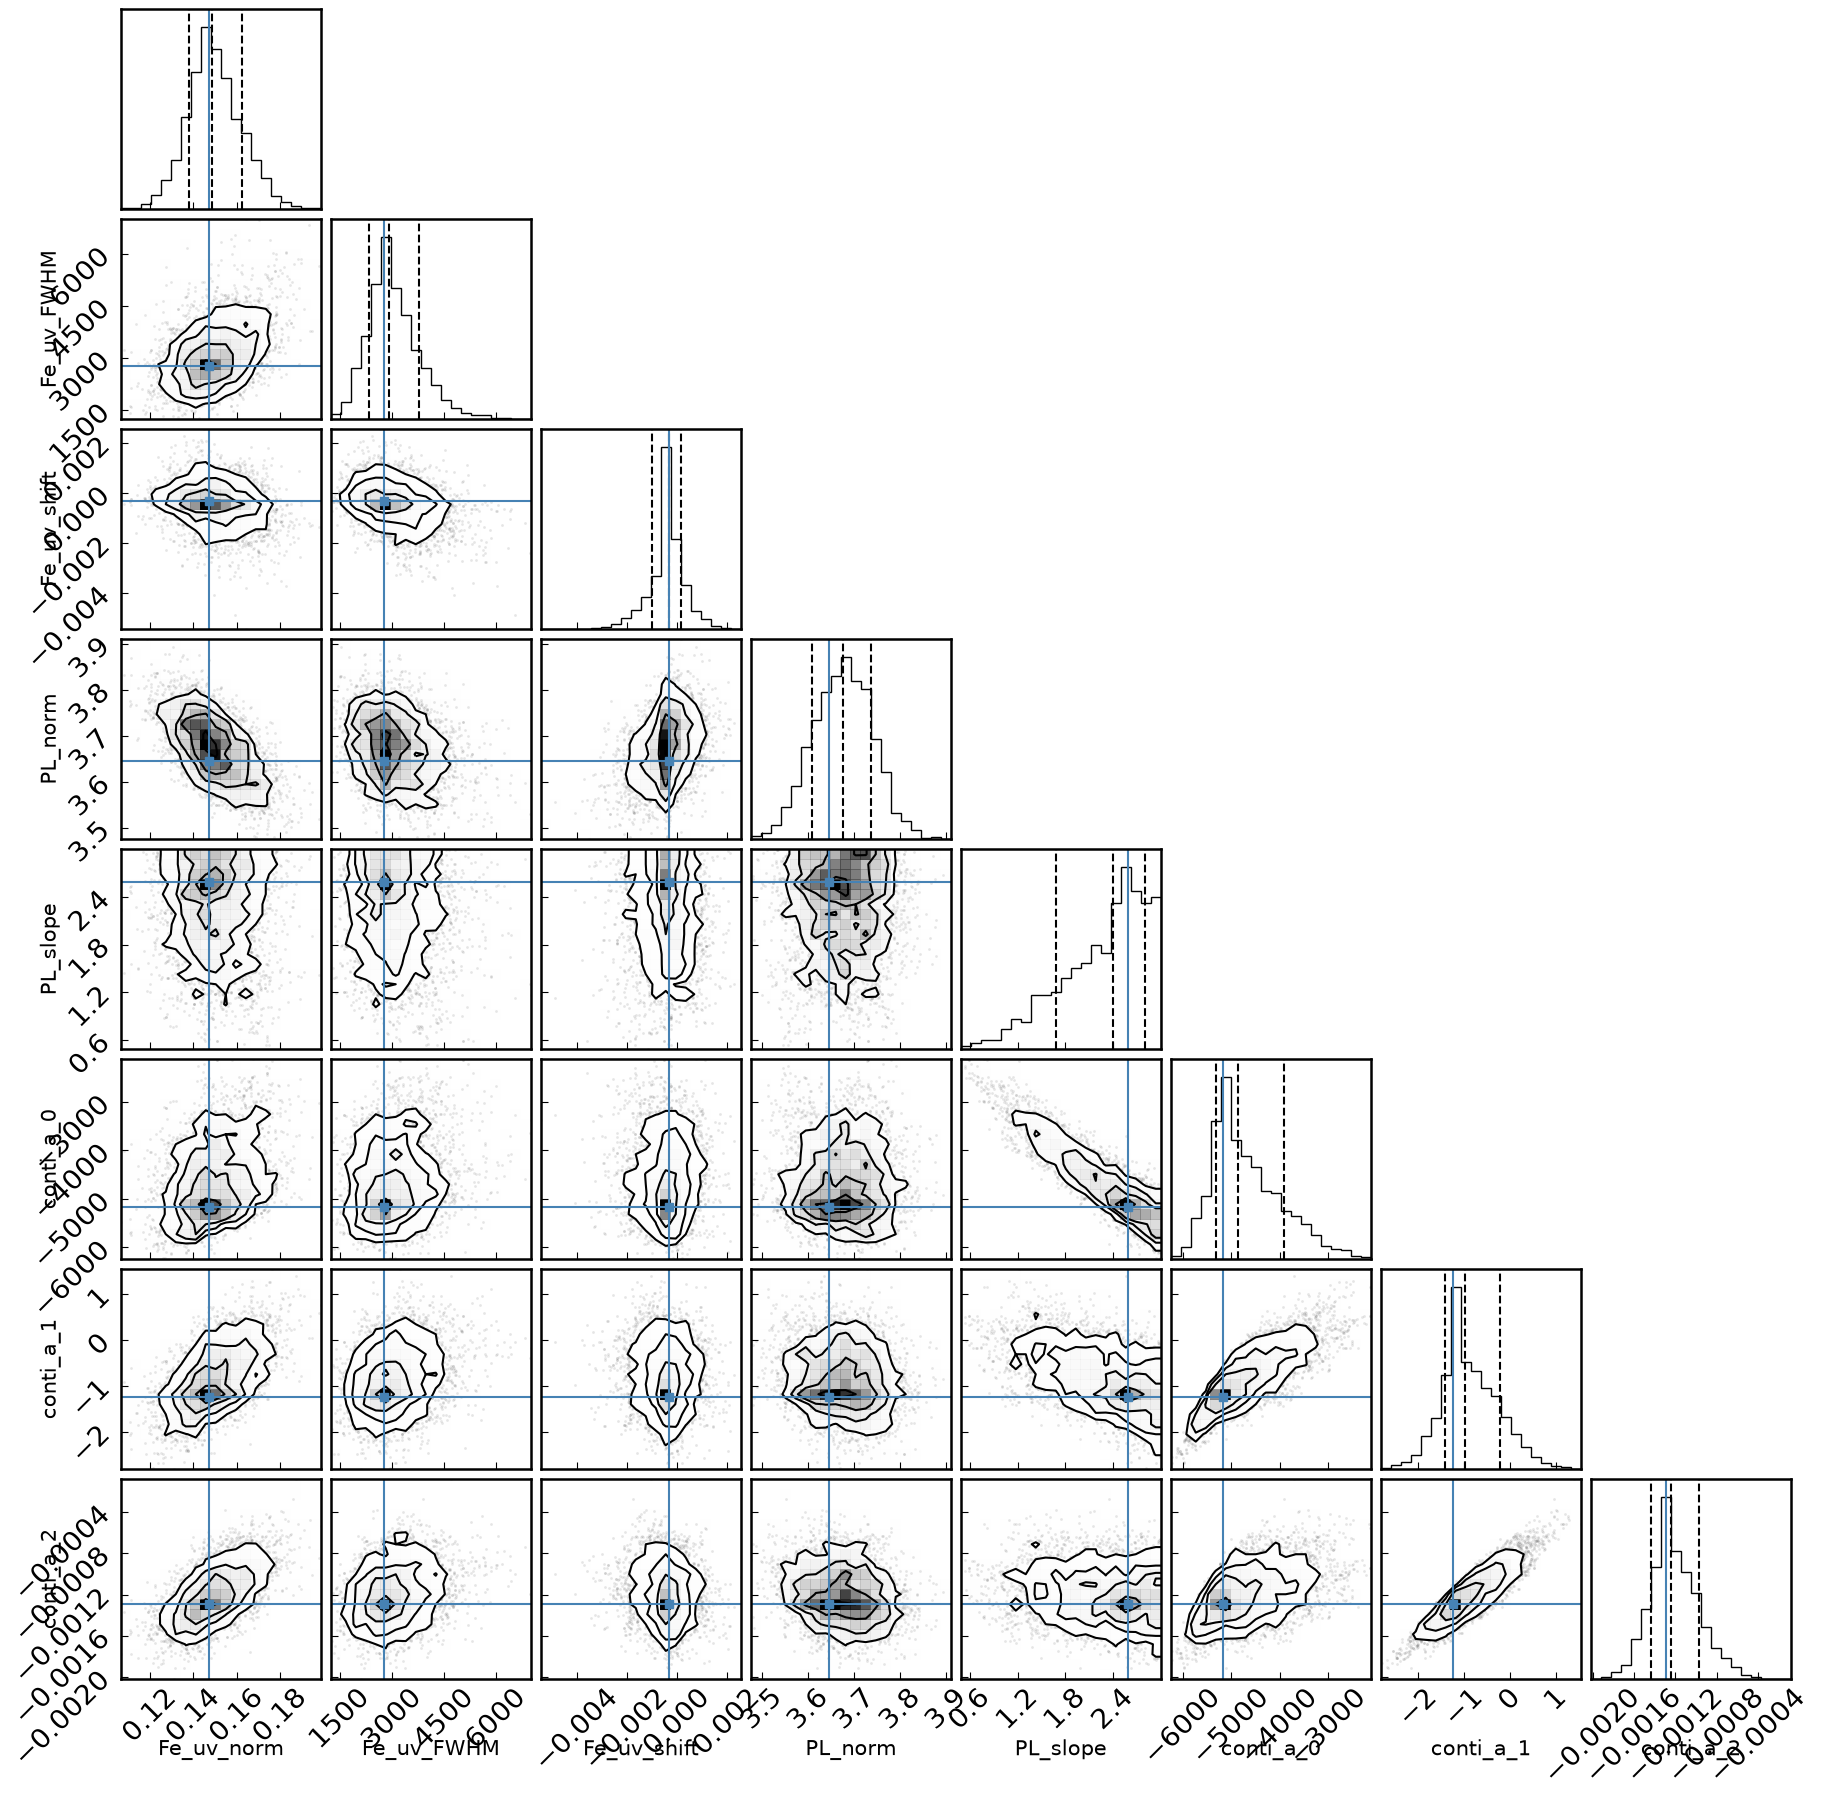

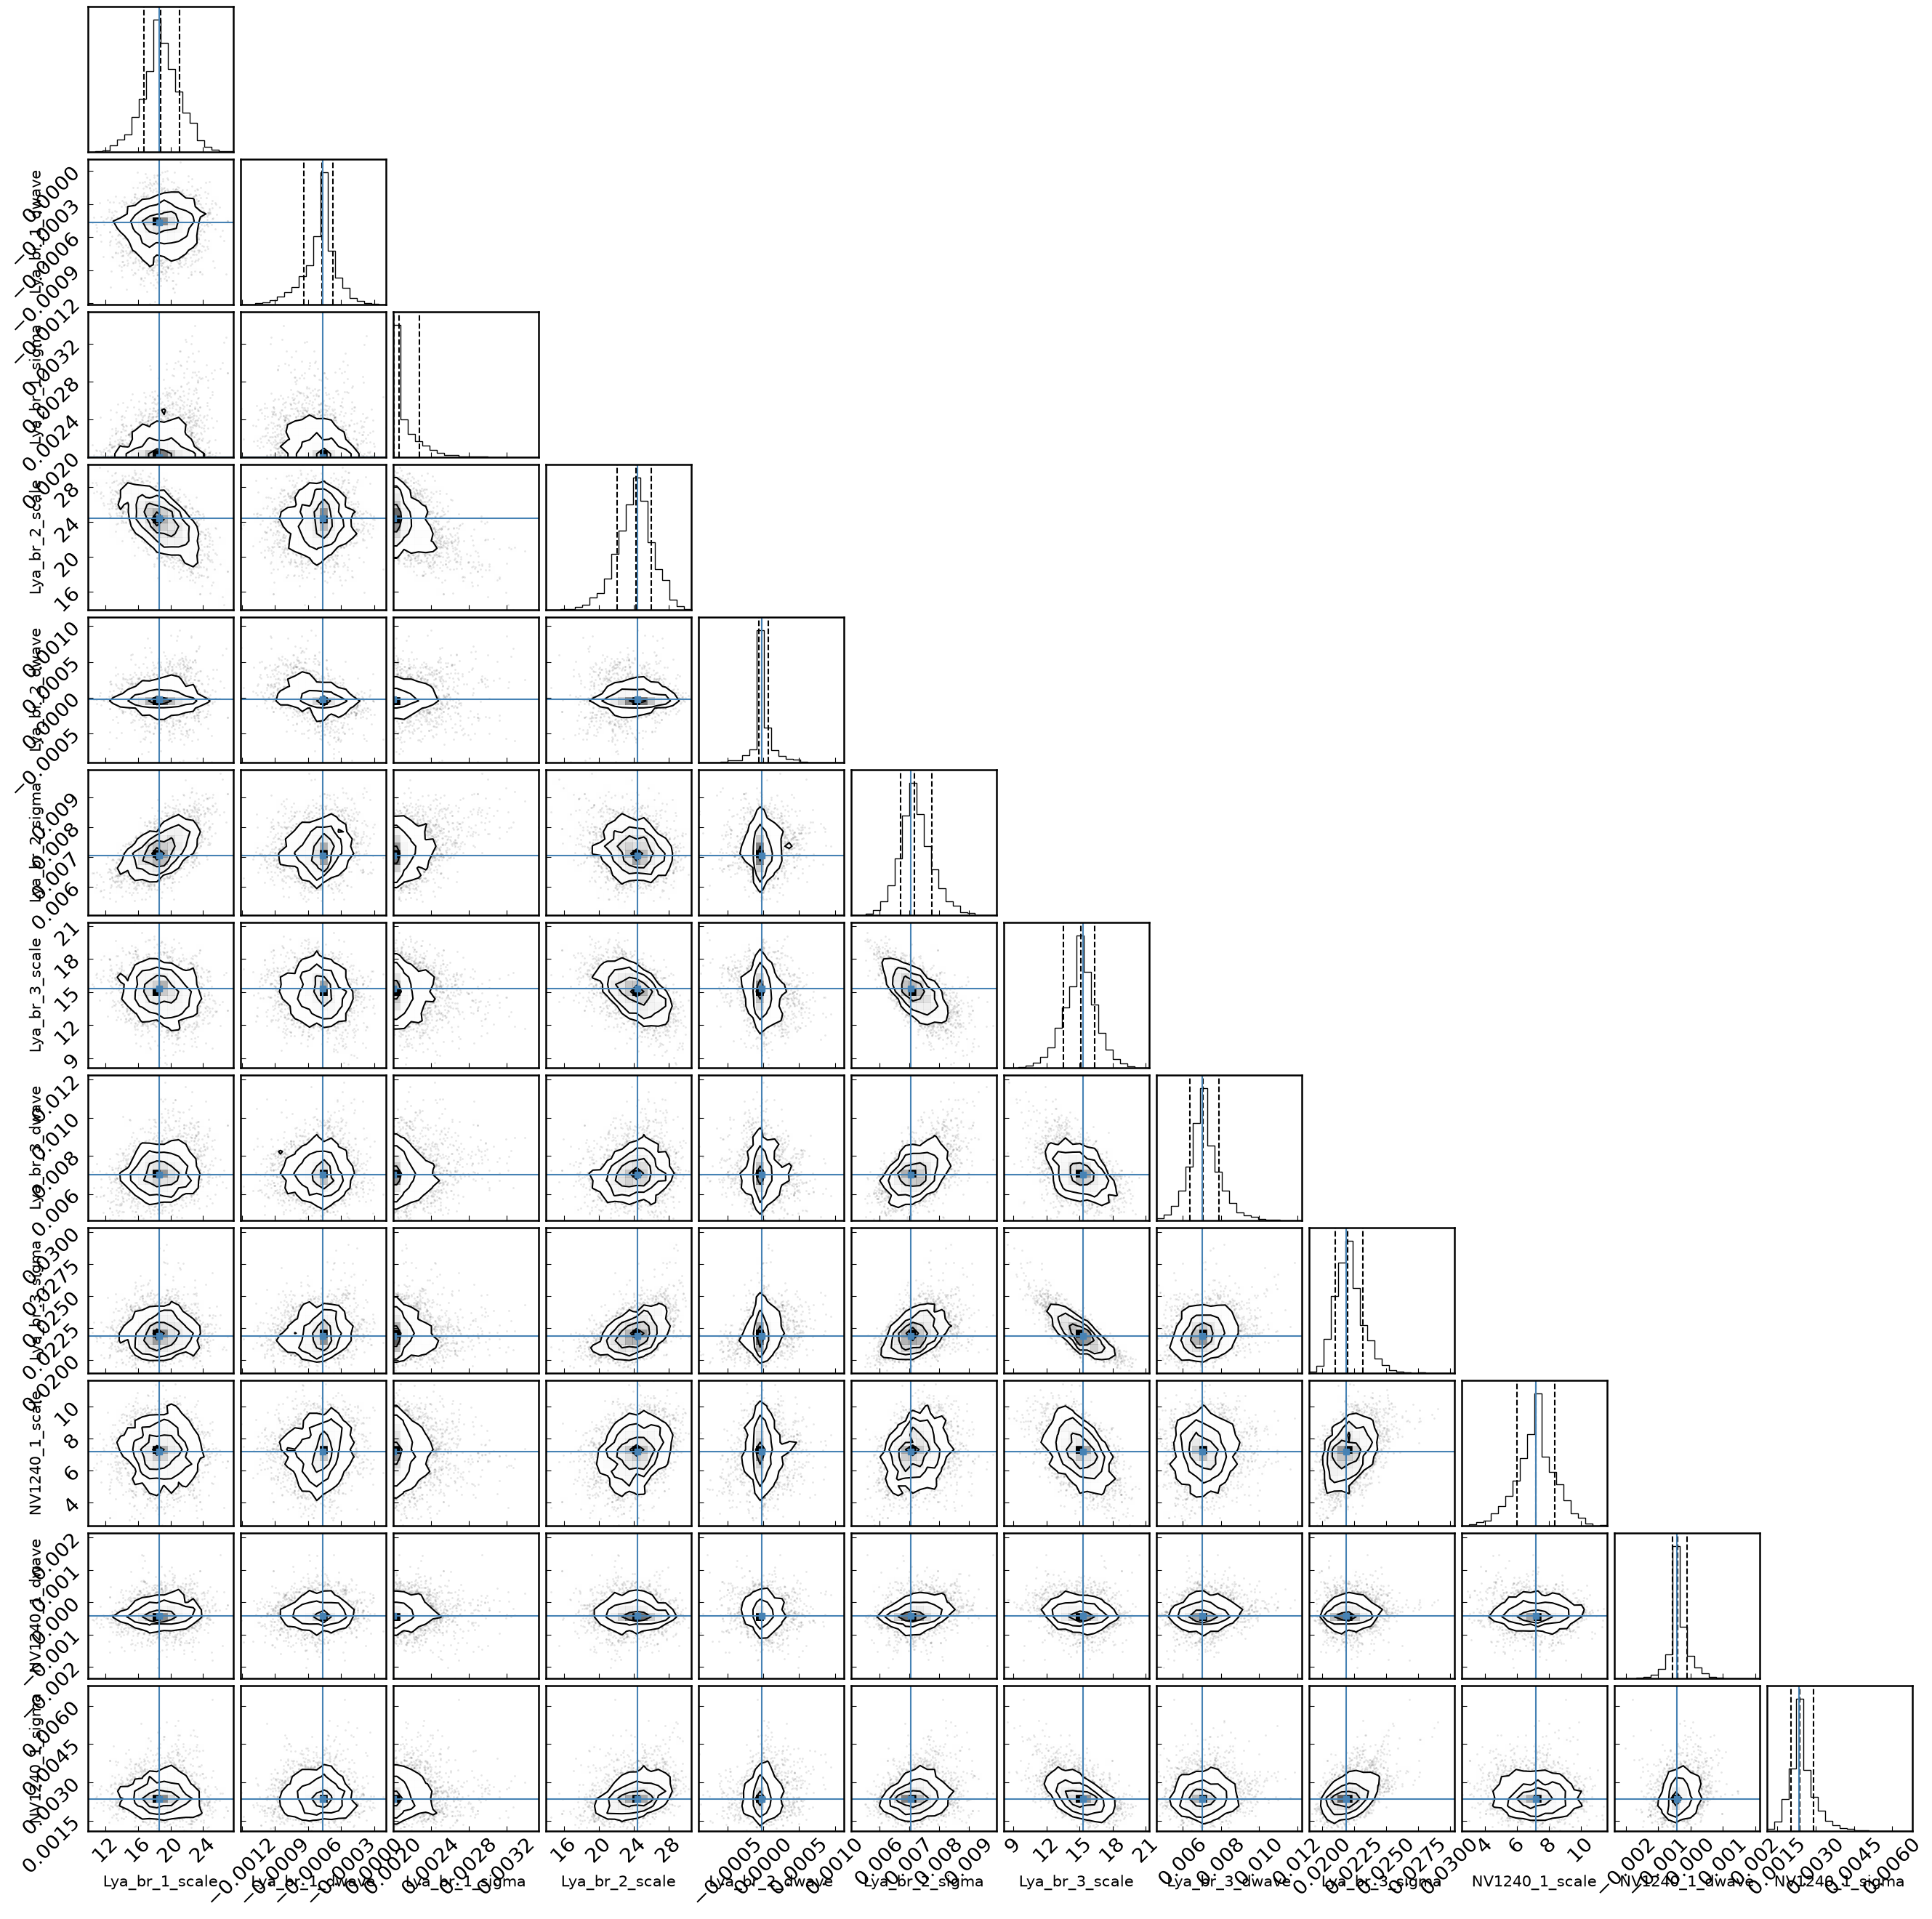

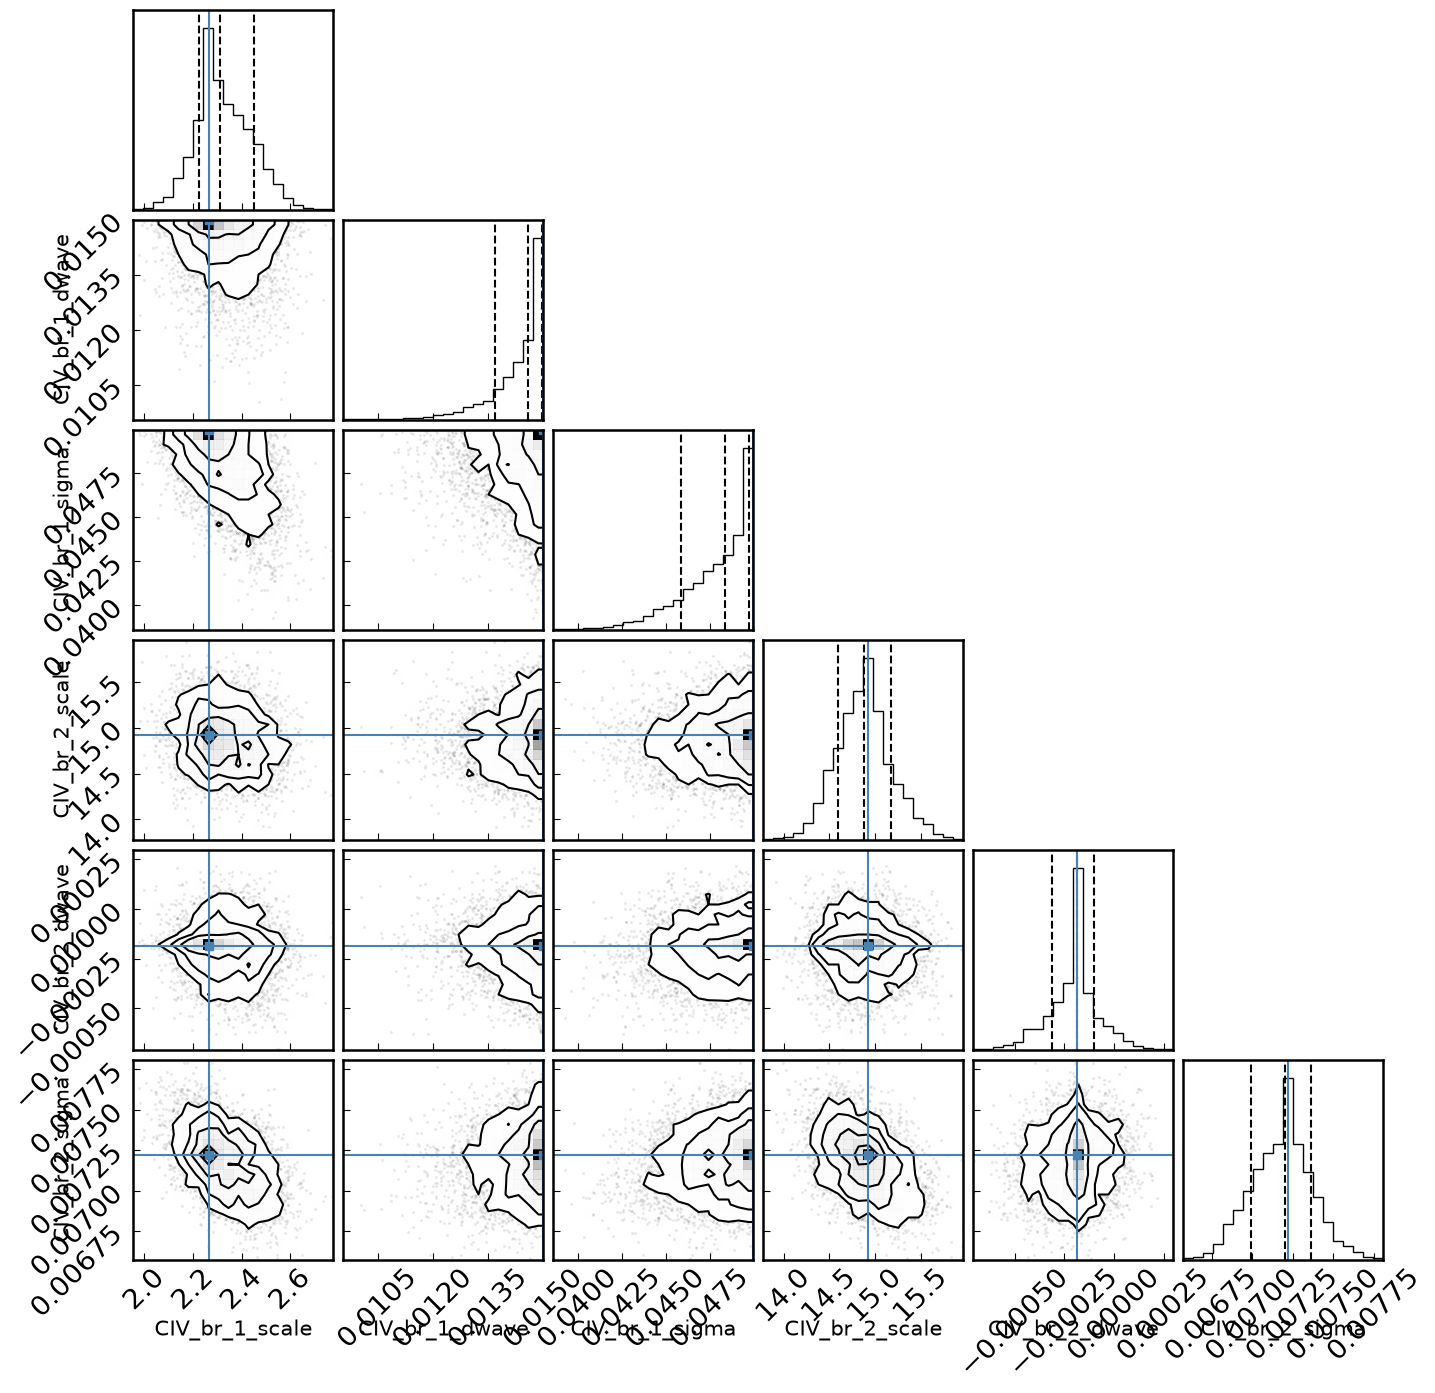

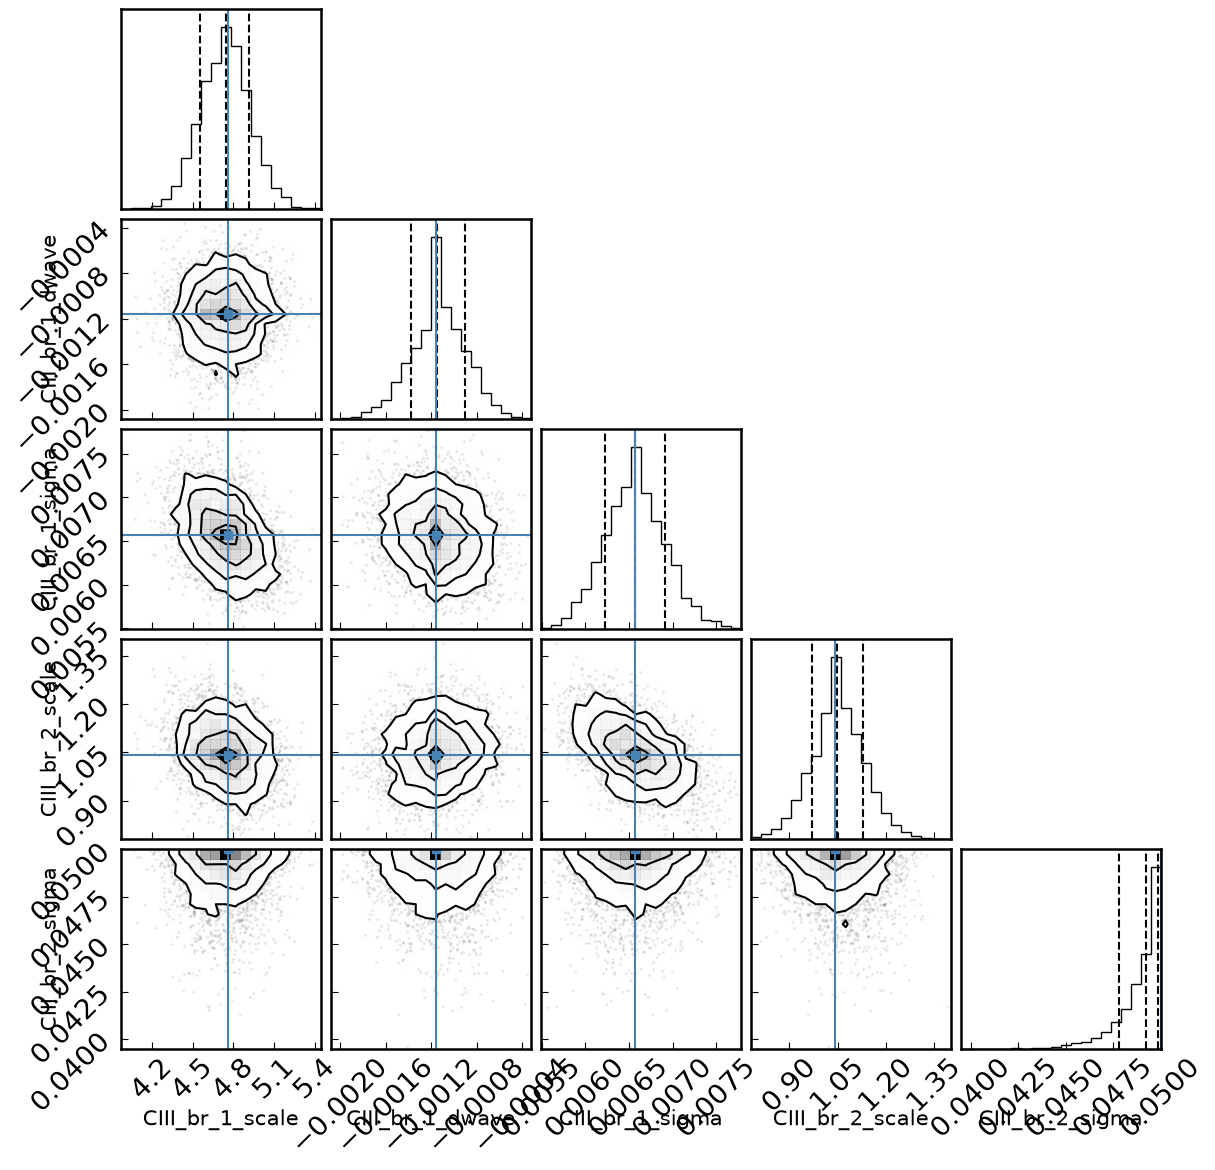

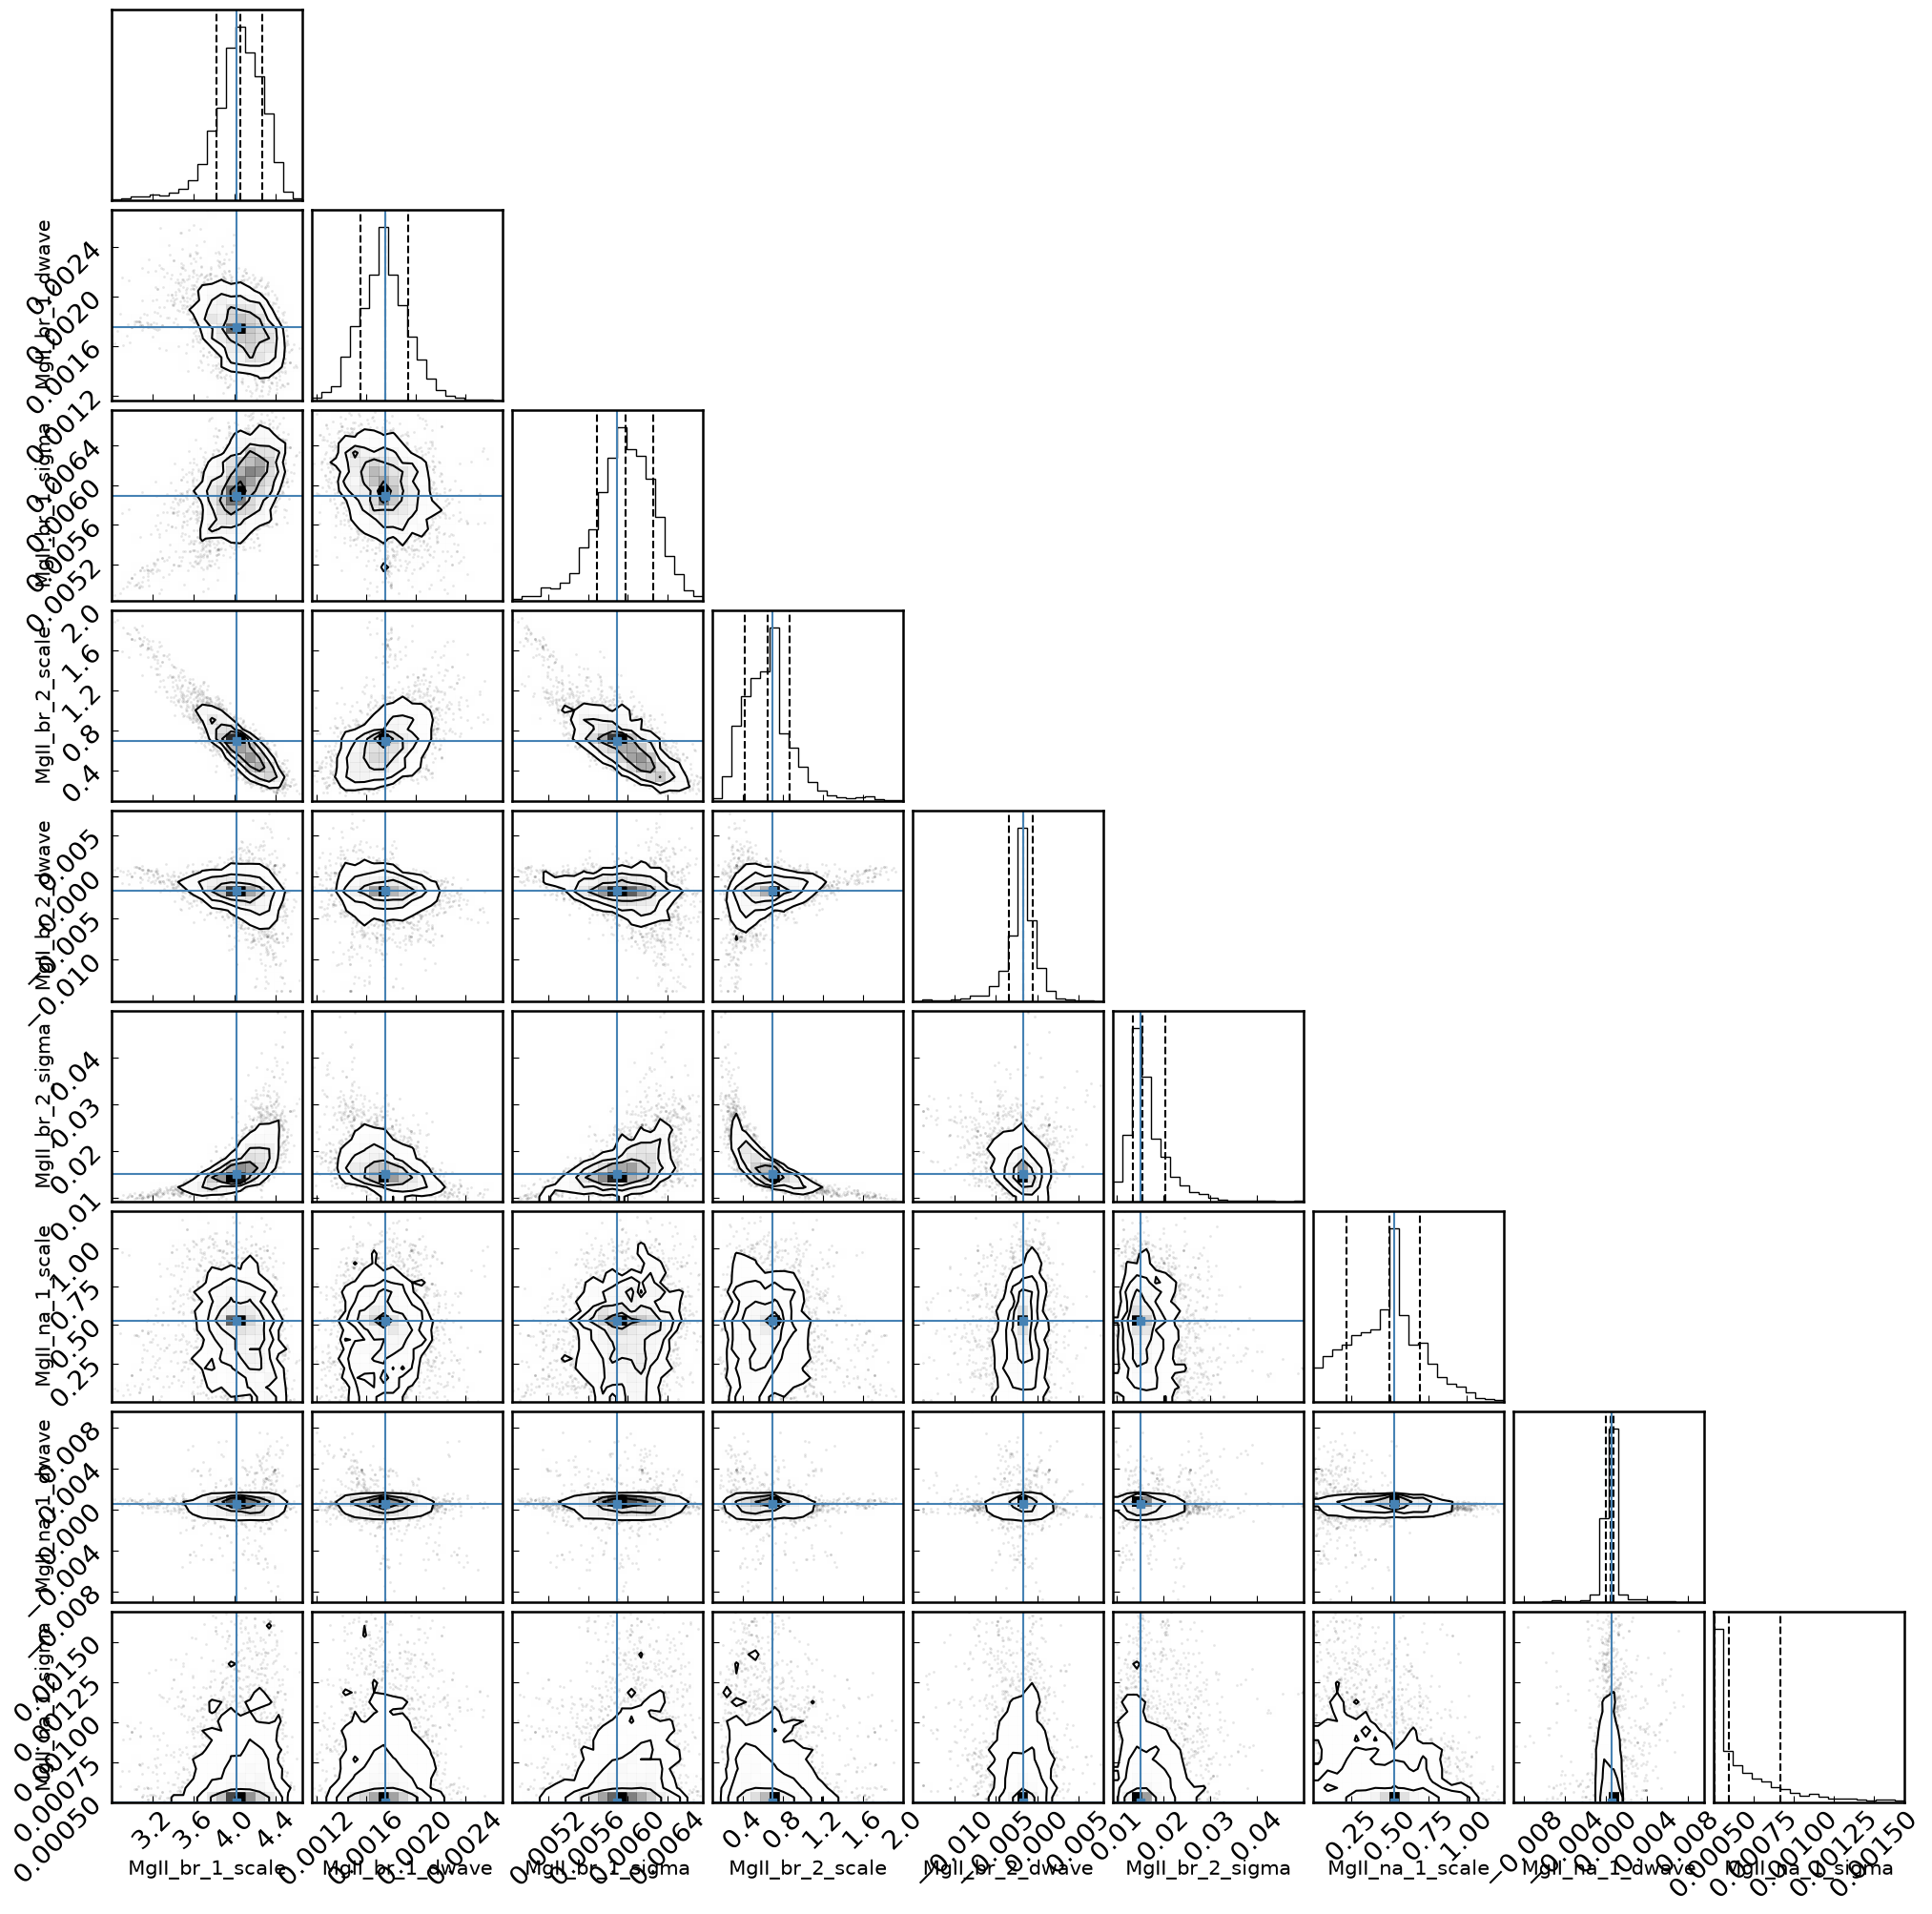

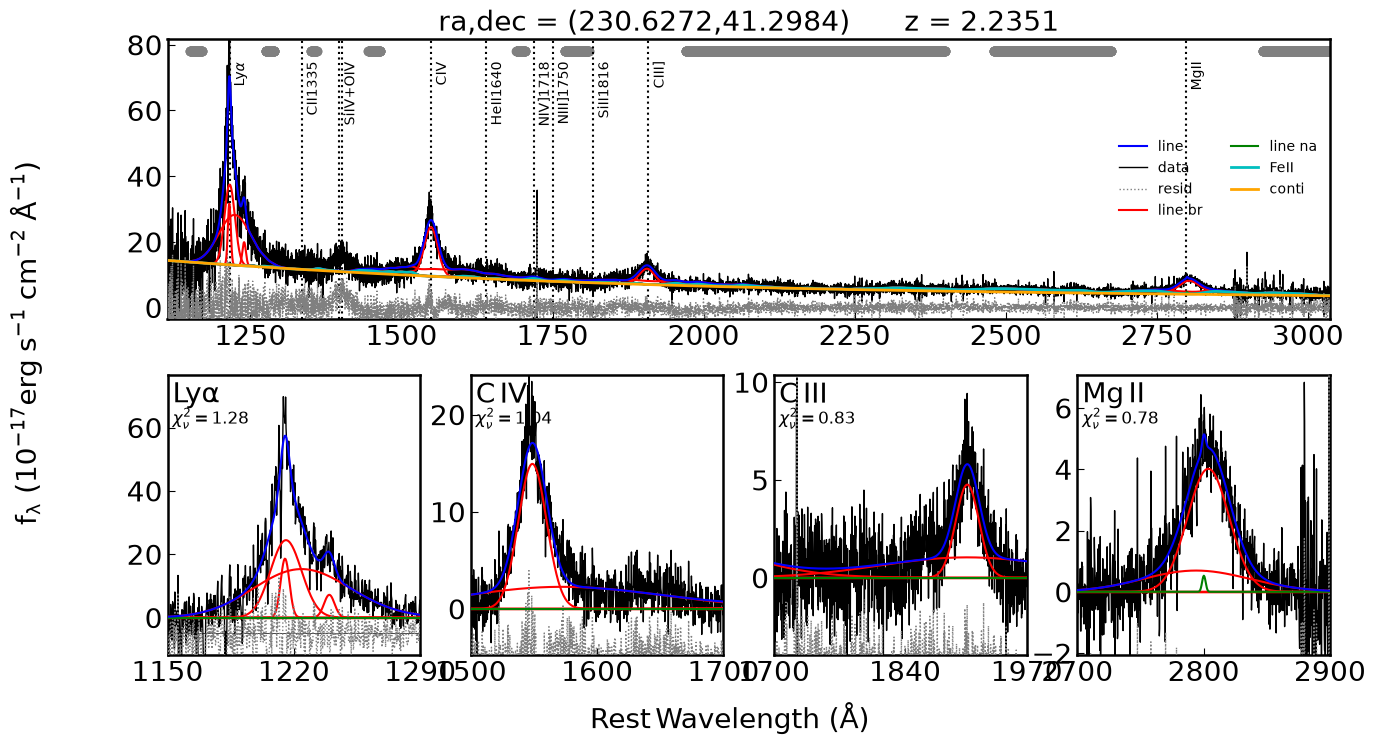

In [12]:
q_mcmc = QSOFit(lam, flux, err, z, ra=ra, dec=dec, path=path_ex)

start = timeit.default_timer()
# Do the fitting
q_mcmc.Fit(name=None, nsmooth=1, deredden=True, reject_badpix=False, wave_range=None, \
           wave_mask=None, decompose_host=True, host_prior=False, decomp_na_mask=True, npca_gal=5, npca_qso=10, qso_type='CZBIN1',
           Fe_uv_op=True, poly=True, rej_abs_conti=False, \
           MCMC=True, epsilon_jitter=0, nburn=10, nsamp=400, nthin=10, linefit=True, save_result=True, \
           plot_fig=True, save_fig=False, plot_corner=True, kwargs_plot={'save_fig_path': '.'}, save_fits_name=None,
           verbose=False)

end = timeit.default_timer()


## BH mass estimate 

In [ ]:
lines = dict(zip(q_mle.line_result_name, q_mle.line_result))
continuum = dict(zip(q_mle.conti_result_name, q_mle.conti_result))

fwhm_mgii = float(lines["MgII_whole_br_fwhm"])  # km/s
log_l3000 = float(continuum["L3000"])          # log10(λLλ in erg/s)

log_m_bh = 6.86 + 2 * np.log10(fwhm_mgii / 1000) + 0.5 * (log_l3000 - 44)


4571.906639349798 45.61743714202948


In [16]:
log_m_bh = 6.86 + 2 * np.log10(fwhm_mgii / 1000) + 0.5 * (log_l3000 - 44)
print(f"M_BH = {10**log_m_bh:.2e} solar masses")

M_BH = 9.75e+08 solar masses


## Fits both bright and dim

In [17]:
epoch_fits = {}

for epoch, hdu in {"bright": bright, "dim": dim}.items():
    spec = coadd_cameras(read_spectra(hdu.filename()))
    band = spec.bands[0]

    wave = spec.wave[band]
    flux = spec.flux[band][0]
    ivar = spec.ivar[band][0]
    good = np.isfinite(flux) & np.isfinite(ivar) & (ivar > 0)

    fit = QSOFit(
        wave[good], flux[good], 1 / np.sqrt(ivar[good]), z,
        ra=ra, dec=dec, path=path_ex,
    )
    # use mc
    fit.Fit(
        name=epoch, nsmooth=1, deredden=True, reject_badpix=False,
        decompose_host=True, host_prior=False, decomp_na_mask=True,
        npca_gal=5, npca_qso=10, qso_type="CZBIN1",
        Fe_uv_op=True, poly=True, rej_abs_conti=False, rej_abs_line=True,
        MC=True, MCMC=False, nsamp=200, linefit=True, save_result=False,
    )
    epoch_fits[epoch] = fit

INFO:spectra.py:453:read_spectra: iotime 0.024 sec to read spectra from:  coadd-5-1766-20210519-39633100518459964.fits at 2026-11-28T00:40:05.002009


INFO:desiutil.log.dlm58.info:iotime 0.024 sec to read spectra from:  coadd-5-1766-20210519-39633100518459964.fits at 2026-11-28T00:40:05.002009


INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.096 [sec]


INFO:desiutil.log.dlm58.info:coadding spectra across cameras took: 0.096 [sec]


INFO:spectra.py:453:read_spectra: iotime 0.023 sec to read spectra from:  coadd-9-11150-20220529-39633100518459964.fits at 2026-11-28T00:42:23.878102


INFO:desiutil.log.dlm58.info:iotime 0.023 sec to read spectra from:  coadd-9-11150-20220529-39633100518459964.fits at 2026-11-28T00:42:23.878102


INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.095 [sec]


INFO:desiutil.log.dlm58.info:coadding spectra across cameras took: 0.095 [sec]


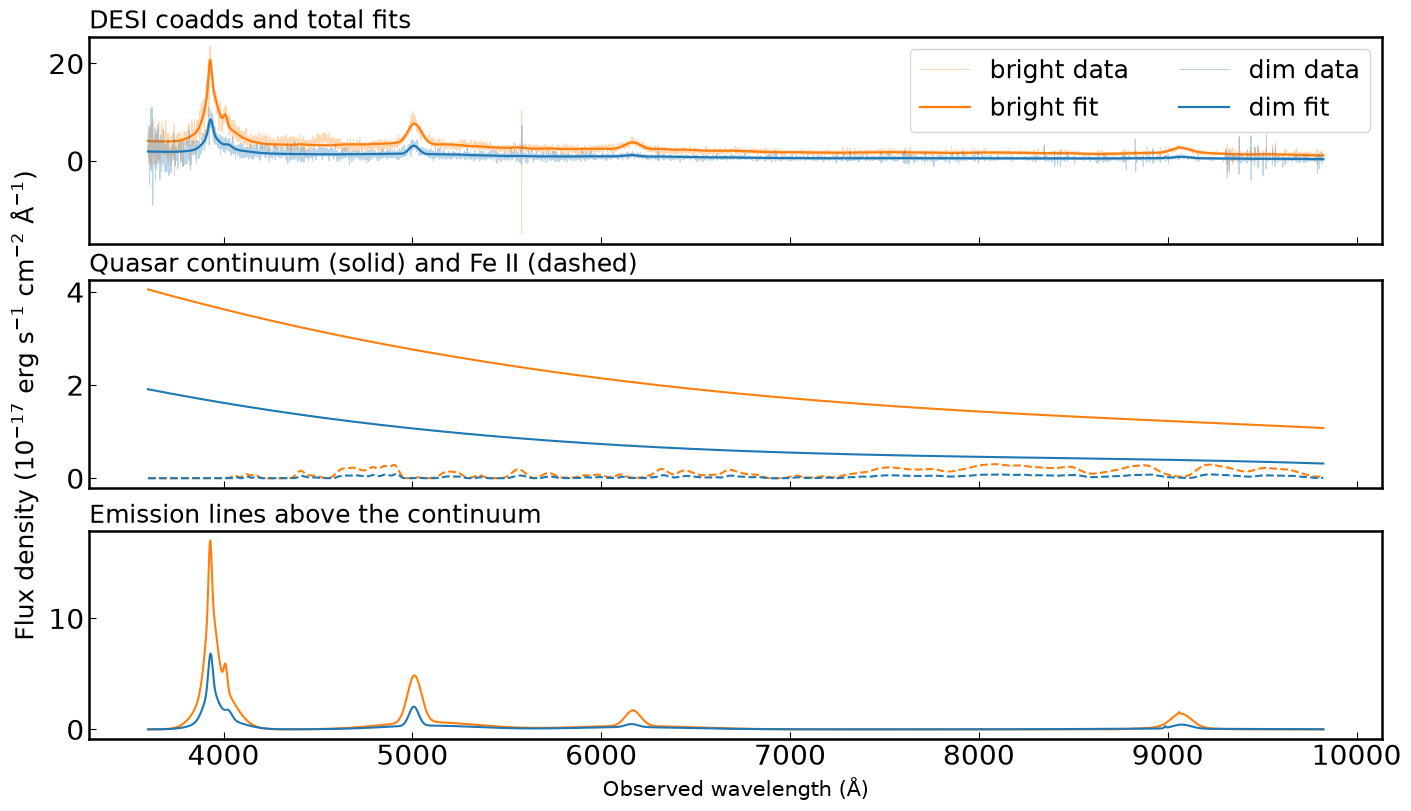

In [21]:
import matplotlib.pyplot as plt
import numpy as np
fig, (ax_total, ax_cont, ax_lines) = plt.subplots(
    3, 1, figsize=(14, 8), sharex=True, layout="constrained"
)
colors = {"bright": "tab:orange", "dim": "tab:blue"}


for epoch, fit in epoch_fits.items():
    color = colors[epoch]
    wave_obs = fit.wave * (1 + fit.z)

    # Put every model component on the raw coadd flux scale.
    err_obs = np.interp(wave_obs, fit.lam_in, fit.err_in)
    err_fit = np.interp(fit.wave, fit.wave_prereduced, fit.err_prereduced)
    scale = err_obs / err_fit

    continuum = fit.PL_poly_BC
    fe_ii = fit.f_conti_model - continuum
    emission = fit.f_line_model
    total = fit.f_conti_model + emission

    if fit.decomposed:
        before_host = np.interp(
            fit.wave, fit.wave_prereduced, fit.flux_prereduced
        )
        host = before_host - fit.flux
        total = total + host
        ax_host.plot(wave_obs, host * scale, color=color, label=epoch)


    ax_total.plot(fit.lam_in, fit.flux_in, color=color, alpha=0.3,
                  lw=0.7, label=f"{epoch} data")
    ax_total.plot(wave_obs, total * scale, color=color, lw=1.6,
                  label=f"{epoch} fit")
    ax_cont.plot(wave_obs, continuum * scale, color=color)
    ax_cont.plot(wave_obs, fe_ii * scale, color=color, ls="--")
    ax_lines.plot(wave_obs, emission * scale, color=color)

ax_total.set_title("DESI coadds and total fits", loc="left")
ax_total.legend(ncol=2)
ax_cont.set_title("Quasar continuum (solid) and Fe II (dashed)", loc="left")
ax_lines.set_title("Emission lines above the continuum", loc="left")
ax_lines.set_xlabel("Observed wavelength (Å)")

fig.supylabel(r"Flux density ($10^{-17}$ erg s$^{-1}$ cm$^{-2}$ Å$^{-1}$)")

# Uncomment to zoom all four panels around Mg II.
# ax_host.set_xlim(8700, 9400)

plt.show()

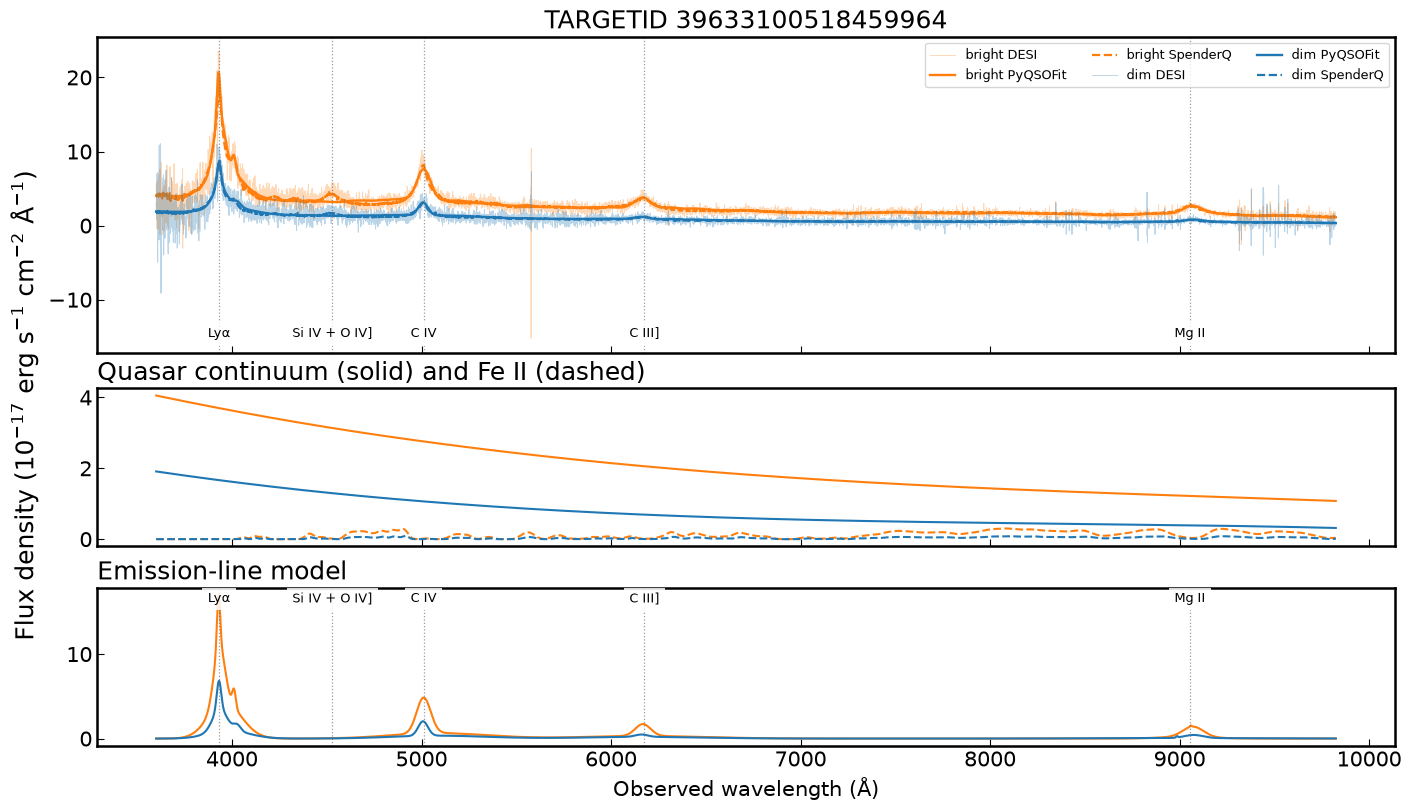

In [33]:
# plot the reconstruction
from pathlib import Path

target_id = "39633100518459964"
recon_dir = (
    Path("/work/10579/prisha/ls6/desi_project/reconstructions") / target_id
)

for epoch, date in {"bright": "20210519", "dim": "20220529"}.items():
    recon_path = recon_dir / date / f"recon_{target_id}_{date}.fits"

    with fits.open(recon_path) as hdul:
        recon = hdul[1]
        z_recon = float(recon.header["Z"])
        norm = float(recon.header["NORM"])
        wave_obs = np.asarray(recon.data["REST_WAVE"]).ravel() * (1 + z_recon)
        flux_obs = np.asarray(recon.data["RECON_FLUX"]).ravel() * (
            norm if norm > 0 else 1.0
        )

    ax_total.plot(
        wave_obs, flux_obs, color=colors[epoch], ls="--", lw=1.6,
        label=f"{epoch} SpenderQ",
    )

epochs = {
    "bright": ("20210519", "tab:orange"),
    "dim": ("20220529", "tab:blue"),
}

fig, (ax_total, ax_cont, ax_lines) = plt.subplots(
    3, 1, figsize=(14, 8), sharex=True, layout="constrained",
    gridspec_kw={"height_ratios": [2, 1, 1]},
)

for epoch, (date, color) in epochs.items():
    fit = epoch_fits[epoch]

    # Put the PyQSOFit models on the original coadd flux scale.
    wave_obs = fit.wave * (1 + fit.z)
    err_obs = np.interp(wave_obs, fit.lam_in, fit.err_in)
    err_fit = np.interp(fit.wave, fit.wave_prereduced, fit.err_prereduced)
    scale = err_obs / err_fit

    continuum = fit.PL_poly_BC
    fe_ii = fit.f_conti_model - continuum
    emission = fit.f_line_model
    total = fit.f_conti_model + emission

    ax_total.plot(fit.lam_in, fit.flux_in, color=color, alpha=0.3,
                  lw=0.7, label=f"{epoch} DESI")
    ax_total.plot(wave_obs, total * scale, color=color,
                  lw=1.7, label=f"{epoch} PyQSOFit")
    ax_cont.plot(wave_obs, continuum * scale, color=color)
    ax_cont.plot(wave_obs, fe_ii * scale, color=color, ls="--")
    ax_lines.plot(wave_obs, emission * scale, color=color)

    # Restore the SpenderQ reconstruction's observed wavelength and flux scale.
    recon_path = recon_dir / date / f"recon_{target_id}_{date}.fits"
    with fits.open(recon_path) as hdul:
        recon = hdul[1]
        z_recon = float(recon.header["Z"])
        norm = float(recon.header["NORM"])
        recon_wave = np.asarray(recon.data["REST_WAVE"]).ravel() * (1 + z_recon)
        recon_flux = np.asarray(recon.data["RECON_FLUX"]).ravel()
        recon_flux = recon_flux * (norm if norm > 0 else 1.0)

    ax_total.plot(recon_wave, recon_flux, color=color, ls="--",
                  lw=1.6, label=f"{epoch} SpenderQ")

broad_lines = {
    "Lyα": 1215.67, "Si IV + O IV]": 1400.0, "C IV": 1549.0,
    "C III]": 1909.0, "Mg II": 2798.75,
}

for label, wave_rest in broad_lines.items():
    center = wave_rest * (1 + epoch_fits["bright"].z)

    for ax, y, va in ((ax_total, 0.04, "bottom"), (ax_lines, 0.97, "top")):
        ax.axvline(center, color="0.4", ls=":", lw=0.9, alpha=0.65)
        ax.text(
            center, y, label,
            transform=ax.get_xaxis_transform(),
            ha="center", va=va, fontsize=9, clip_on=True,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85},
        )

ax_total.set_title(f"TARGETID {target_id}")
ax_total.legend(ncol=3, fontsize=9)
ax_cont.set_title("Quasar continuum (solid) and Fe II (dashed)", loc="left")
ax_lines.set_title("Emission-line model", loc="left")
ax_lines.set_xlabel("Observed wavelength (Å)")
fig.supylabel(r"Flux density ($10^{-17}$ erg s$^{-1}$ cm$^{-2}$ Å$^{-1}$)")

# Uncomment to zoom all three panels around Mg II.
# ax_lines.set_xlim(8700, 9400)
out_dir = "/work/11161/kanyuni/ls6/quassiQ_project/fitting/test"
os.makedirs(out_dir, exist_ok=True)

fig.savefig(os.path.join(out_dir, "39633100518459964_fit_spender.png"), dpi=200)
plt.show()

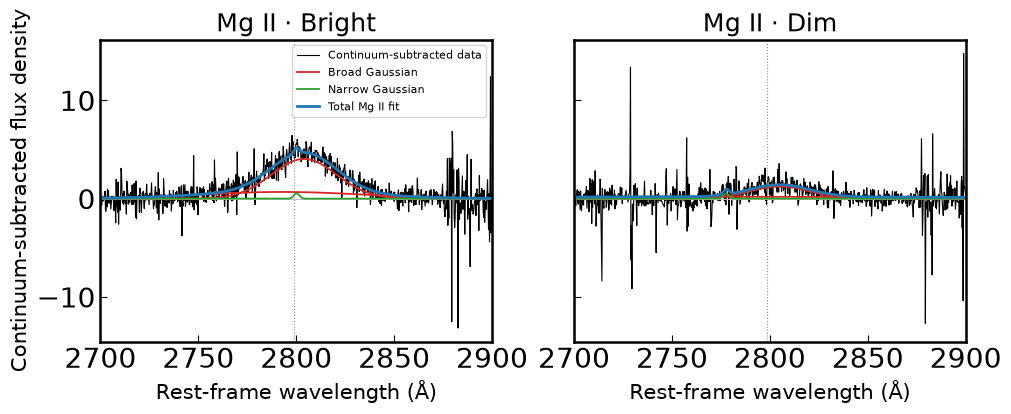

In [28]:
#individual Gaussian components
fig, axes = plt.subplots(
    1, 2, figsize=(10, 4), sharex=True, sharey=True, layout="constrained"
)
wave_model = np.linspace(2700, 2900, 1000)  # rest-frame Å

for ax, epoch in zip(axes, ("bright", "dim")):
    fit = epoch_fits[epoch]
    params = dict(zip(fit.gauss_result_name, fit.gauss_result))
    in_window = (fit.wave >= 2700) & (fit.wave <= 2900)

    ax.plot(fit.wave[in_window], fit.line_flux[in_window],
            color="black", lw=0.8, label="Continuum-subtracted data")
    ax.axhline(0, color="0.75", lw=0.7)
    ax.axvline(2798.75, color="0.55", ls=":", lw=0.8)

    total = np.zeros_like(wave_model)
    for name in params:
        if not (name.lower().startswith("mgii_") and name.endswith("_scale")):
            continue

        stem = name.removesuffix("_scale")
        gaussian = [float(params[f"{stem}_{key}"])
                    for key in ("scale", "centerwave", "sigma")]
        component = fit.Onegauss(np.log(wave_model), gaussian)
        total += component

        broad = fit.CalFWHM(gaussian[2]) >= 1200  # PyQSOFit's plot threshold
        ax.plot(wave_model, component,
                color="tab:red" if broad else "tab:green",
                lw=1.3, label="Broad Gaussian" if broad else "Narrow Gaussian")

    ax.plot(wave_model, total, color="tab:blue", lw=2, label="Total Mg II fit")
    ax.set(xlim=(2700, 2900), title=f"Mg II · {epoch.capitalize()}",
           xlabel="Rest-frame wavelength (Å)")

axes[0].set_ylabel("Continuum-subtracted flux density")
handles, labels = axes[0].get_legend_handles_labels()
legend = dict(zip(labels, handles))
axes[0].legend(legend.values(), legend.keys(), fontsize=8)

plt.show()

In [18]:
rows = []
for epoch, fit in epoch_fits.items():
    lines = dict(zip(fit.line_result_name, fit.line_result))
    cont = dict(zip(fit.conti_result_name, fit.conti_result))

    fwhm = float(lines["MgII_whole_br_fwhm"])
    fwhm_err = float(lines["MgII_whole_br_fwhm_err"])
    log_l3000 = float(cont["L3000"])
    log_l3000_err = float(cont["L3000_err"])

    if (not np.all(np.isfinite([fwhm, fwhm_err, log_l3000, log_l3000_err]))
            or fwhm <= 0 or log_l3000 <= -1
            or fwhm_err < 0 or log_l3000_err < 0):
        raise ValueError(f"{epoch}: invalid Mg II width, L3000, or uncertainty")

    log_mass = 6.86 + 2 * np.log10(fwhm / 1000) + 0.5 * (log_l3000 - 44)
    mass_err = np.hypot(2 * fwhm_err / (fwhm * np.log(10)), 0.5 * log_l3000_err)
    rows.append((epoch, fwhm, log_l3000, log_mass, mass_err))

results = pd.DataFrame(rows, columns=[
    "epoch", "FWHM_km_s", "log_L3000", "log_MBH", "log_MBH_err",
]).set_index("epoch")
display(results.round(3))

delta = results.loc["bright", "log_MBH"] - results.loc["dim", "log_MBH"]
delta_err = np.hypot(results.loc["bright", "log_MBH_err"],
                     results.loc["dim", "log_MBH_err"])
print(f"Bright − dim: {delta:+.3f} ± {delta_err:.3f} dex")

,FWHM_km_s,log_L3000,log_MBH,log_MBH_err
epoch,,,,
bright,4584.395,45.617,8.991,0.030
dim,4274.525,45.095,8.669,0.108


Bright − dim: +0.322 ± 0.112 dex


In [29]:
# using CIV
for epoch, fit in epoch_fits.items():
    lines = dict(zip(fit.line_result_name, fit.line_result))
    continuum = dict(zip(fit.conti_result_name, fit.conti_result))

    fwhm_civ = float(lines["CIV_whole_br_fwhm"])  # km/s
    log_l1350 = float(continuum["L1350"])

    if not np.isfinite(fwhm_civ) or fwhm_civ <= 0 or not np.isfinite(log_l1350) or log_l1350 <= -1:
        print(f"{epoch}: no valid C IV mass estimate")
        continue

    log_m_bh_civ = 6.66 + 2 * np.log10(fwhm_civ / 1000) + 0.53 * (log_l1350 - 44)
    print(f"{epoch}: log10(M_BH / M_sun) = {log_m_bh_civ:.2f} (C IV)")

bright: log10(M_BH / M_sun) = 9.12 (C IV)
dim: log10(M_BH / M_sun) = 8.62 (C IV)


# Black hole mass, Eddington ratio, and accretion rate

These notes describe how to use the PyQSOFit results for the bright and dim epochs of DESI target 39633100518459964.

## 1. Estimate the black hole mass from Mg II

Use the FWHM of the combined broad Mg II profile in km/s and the continuum luminosity at rest-frame 3000 Å. PyQSOFit reports these as `MgII_whole_br_fwhm` and `L3000`. The `L3000` field already contains the base-10 logarithm of the monochromatic luminosity in erg/s.

$$
\log_{10}\!\left(\frac{M_{\rm BH}}{M_\odot}\right)
= 6.86
+ 2\log_{10}\!\left(\frac{\mathrm{FWHM}_{\mathrm{Mg\,II}}}{1000\ \mathrm{km\,s^{-1}}}\right)
+ 0.5\left(\log_{10} L_{3000}-44\right).
$$

[Vestergaard & Osmer (2009), Equation 1](https://doi.org/10.1088/0004-637X/699/1/800)

## 2. Estimate the bolometric luminosity

Convert the fitted `L3000` from log units and multiply by the bolometric correction of 5.15.

$$
L_{\rm bol} = 5.15\,L_{3000}.
$$

[Shen et al. (2011)](https://arxiv.org/abs/1006.5178) · [Richards et al. (2006)](https://arxiv.org/abs/astro-ph/0601558)

## 3. Calculate the Eddington ratio

The Eddington ratio is the fraction of the Eddington luminosity at which the quasar radiates.

$$
L_{\rm Edd} = 1.26\times10^{38}
\left(\frac{M_{\rm BH}}{M_\odot}\right)\ \mathrm{erg\,s^{-1}},
\qquad
\lambda_{\rm Edd} = \frac{L_{\rm bol}}{L_{\rm Edd}}.
$$

[Supermassive black holes are growing slowly by z ~ 5, §2.2.1](https://academic.oup.com/mnras/article/531/2/2245/7676860)

## 4. Estimate the mass accretion rate

Assume a radiative efficiency of $\eta=0.10$. The inferred rate scales as $1/\eta$.

$$
\dot M = \frac{L_{\rm bol}}{\eta c^2}
\approx 0.177
\left(\frac{L_{\rm bol}}{10^{45}\ \mathrm{erg\,s^{-1}}}\right)
\left(\frac{0.10}{\eta}\right)
M_\odot\,\mathrm{yr^{-1}}.
$$

[Meusinger & Weiss (2013), Equation 4](https://doi.org/10.1051/0004-6361/201322410)


In [32]:
# accretion rate, bolometric etc
accretion = results[["log_L3000"]].copy()
mass_ref = 10**results.loc["bright", "log_MBH"]  # solar masses

# Bolometric luminosity and Eddington luminosity, both in erg/s.
l_bol = 5.15 * 10**accretion["log_L3000"]
l_edd = 1.26e38 * mass_ref

accretion["log_Lbol"] = np.log10(l_bol)
accretion["eddington_ratio"] = l_bol / l_edd

eta = 0.10  # assumed radiative efficiency
luminosity = l_bol.to_numpy() * u.erg / u.s
accretion["Mdot_Msun_per_yr"] = (luminosity / (eta * c**2)).to_value(
    u.M_sun / u.yr
)

display(accretion.round(3))

,log_L3000,log_Lbol,eddington_ratio,Mdot_Msun_per_yr
epoch,,,,
bright,45.617,46.329,0.173,3.769
dim,45.095,45.807,0.052,1.131
